# Project 1 — Notebook 2: Cleaning the BRFSS 2015 data

**F!1-Cardiaque** — Yahya Skalli, Sara El Harti, Rania El Kasmi
**Course** CS-433 Machine Learning — Class Project 1 (MICHD prediction)

## What this notebook does

Notebook `01_explore_data.ipynb` looked at the raw file and showed *what the data looks like*.
This notebook is the **single source of truth for the cleaned dataset**: it takes the raw CSV
files, applies every decision we made, documents *why* each decision was taken, and writes the
result to disk so that the modelling notebook never has to touch the raw data again.

Everything downstream (feature engineering, cross-validation, the AIcrowd submission) reads the
two artefacts produced at the end of this notebook:

| File | Content |
|---|---|
| `data/cache/cleaned.npz` | cleaned train matrix, cleaned test matrix, labels, ids, column names |
| `notebooks/column_types.json` | for each surviving column, whether it is binary / nominal / ordinal / continuous |

## Constraints of the project

* **NumPy only** for anything that touches the model. `matplotlib` is used for visualisation only.
* No `pandas`, no `scikit-learn`. Every transformation below is plain NumPy, written by us.
* The test set must go through **exactly the same** transformations as the train set, with
  statistics (percentiles, means) estimated **on the train set only**.

## 1. Setup

Imports, paths, and the project root added to `sys.path` so that `implementations.py`
(one directory up) is importable from `notebooks/`.

Nothing here depends on the data yet.

In [1]:
import os
import re
import sys
import json
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- paths
# This notebook is expected to live in  project-1/notebooks/
HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
DATA = ROOT / "data"
CACHE = DATA / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

# project-1/ on the path so that `import implementations` works
sys.path.insert(0, str(ROOT))

np.set_printoptions(suppress=True, linewidth=140)
np.random.seed(42)

print("notebook dir :", HERE)
print("project root :", ROOT)
print("data dir     :", DATA, "(exists:", DATA.exists(), ")")
print("numpy        :", np.__version__)

notebook dir : /home/projects-ML-2026/project-1/notebooks
project root : /home/projects-ML-2026/project-1
data dir     : /home/projects-ML-2026/project-1/data (exists: True )
numpy        : 2.2.6


### 1.1 Locating the files

We need:

* `x_train.csv`, `x_test.csv`, `y_train.csv` — the dataset,
* `brfss2015_rules_full.json` — the machine-readable codebook we extracted from the official
  CDC PDF (*Behavioral Risk Factor Surveillance System 2015 Codebook Report*). It contains, for
  each of the 330 documented columns: the survey question, the value labels, and the list of
  codes that mean *missing*, *none* or *off-scale*.

In [2]:
def find_file(name, roots):
    """Return the first file called `name` found under any of `roots` (recursive)."""
    for r in roots:
        r = Path(r)
        if not r.exists():
            continue
        hits = sorted(r.rglob(name))
        if hits:
            return hits[0]
    return None

F_XTR = find_file("x_train.csv", [DATA])
F_XTE = find_file("x_test.csv", [DATA])
F_YTR = find_file("y_train.csv", [DATA])
F_CB = find_file("brfss2015_rules_full.json", [HERE, ROOT])

for label, p in [("x_train", F_XTR), ("x_test", F_XTE), ("y_train", F_YTR), ("codebook", F_CB)]:
    size = f"{p.stat().st_size / 1e6:8.2f} MB" if p else "   MISSING"
    print(f"{label:9s} {size}  {p if p else ''}")

missing = [n for n, p in [("x_train.csv", F_XTR), ("x_test.csv", F_XTE),
                          ("y_train.csv", F_YTR), ("brfss2015_rules_full.json", F_CB)] if p is None]
if missing:
    raise FileNotFoundError(
        "Not found: " + ", ".join(missing)
        + f"\nPut the CSV files under {DATA} and the codebook next to this notebook."
    )

x_train     227.38 MB  /home/projects-ML-2026/project-1/data/unzipped/dataset/x_train.csv
x_test       91.71 MB  /home/projects-ML-2026/project-1/data/unzipped/dataset/x_test.csv
y_train       3.47 MB  /home/projects-ML-2026/project-1/data/unzipped/dataset/y_train.csv
codebook      0.18 MB  /home/projects-ML-2026/project-1/notebooks/brfss2015_rules_full.json


### 1.2 Fast loading, with a cache

`np.genfromtxt` on a 300 MB file with 321 columns takes minutes because it has to handle
missing fields. Two tricks make it roughly twenty times faster:

1. Read the whole file as one string and turn every **empty field** into the literal text
   `nan` with a single regular expression. `(?<=,)(?=,|\n)` matches a position that is
   preceded by a comma and followed by a comma or a newline, i.e. exactly an empty field.
   After this substitution the file is a regular numeric CSV and the much faster
   `np.loadtxt` can read it.
2. Save the resulting array as a `.npy` file. Re-running the notebook then loads the binary
   array in a second or two instead of re-parsing the text.

We store the matrices as `float32`: the values are small integers and half the memory means
we can keep the train and test matrices in RAM at the same time. `float` (not `int`) is
required because we are about to put `np.nan` in them, and NumPy integer arrays cannot hold
`nan`.

In [3]:
def read_csv_fast(path, cache_npy, verbose=True):
    """Read a numeric CSV with empty fields into a float32 array + list of column names.

    Uses a .npy cache so that the expensive text parsing happens only once.
    Returns (names, matrix).
    """
    path, cache_npy = Path(path), Path(cache_npy)
    header = path.open().readline().rstrip("\n").split(",")

    if cache_npy.exists() and cache_npy.stat().st_mtime > path.stat().st_mtime:
        M = np.load(cache_npy)
        if verbose:
            print(f"  {path.name:14s} <- cache {cache_npy.name}  {M.shape}")
        return header, M

    t0 = time.time()
    txt = path.read_text()
    txt = txt[txt.index("\n") + 1:]              # drop the header line
    txt = re.sub(r"(?<=,)(?=,|\n)", "nan", txt)  # empty field -> nan
    txt = re.sub(r"(?<=\n)(?=,)", "nan", txt)    # empty *first* field of a row
    M = np.loadtxt(txt.splitlines(), delimiter=",", dtype=np.float32)
    np.save(cache_npy, M)
    if verbose:
        print(f"  {path.name:14s} parsed in {time.time() - t0:5.1f}s -> {M.shape}, cached")
    return header, M


def load_raw():
    """(Re)load the raw data from cache. Cheap, and always returns a fresh copy.

    Every cell that modifies the matrix in place starts by calling this, which makes those
    cells idempotent: running them twice gives the same result as running them once.
    """
    hdr_tr, Mtr = read_csv_fast(F_XTR, CACHE / "x_train.npy", verbose=False)
    hdr_te, Mte = read_csv_fast(F_XTE, CACHE / "x_test.npy", verbose=False)
    return hdr_tr, Mtr, hdr_te, Mte


print("loading (first run parses the CSVs, later runs hit the cache):")
hdr_tr, X_raw_full = read_csv_fast(F_XTR, CACHE / "x_train.npy")
hdr_te, XT_raw_full = read_csv_fast(F_XTE, CACHE / "x_test.npy")
hdr_y, Y_raw = read_csv_fast(F_YTR, CACHE / "y_train.npy")

print("\nx_train:", X_raw_full.shape, "| x_test:", XT_raw_full.shape, "| y_train:", Y_raw.shape)
print("x_train header starts with:", hdr_tr[:6])
print("y_train header            :", hdr_y)

loading (first run parses the CSVs, later runs hit the cache):
  x_train.csv    <- cache x_train.npy  (328135, 322)
  x_test.csv     <- cache x_test.npy  (109379, 322)
  y_train.csv    <- cache y_train.npy  (328135, 2)

x_train: (328135, 322) | x_test: (109379, 322) | y_train: (328135, 2)
x_train header starts with: ['Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY']
y_train header            : ['Id', '_MICHD']


### 1.3 Separating the ids from the features, and normalising the label

The first column of each file is `Id`. It is a row number, not a measurement, so it is kept
aside (we need it to write the submission file) and removed from the feature matrix.

The label `_MICHD` is coded `1 = yes, 2 = no` in the raw BRFSS file and the project ships it
as `-1 / 1`. Logistic regression as we implement it expects **`y ∈ {0, 1}`**, because the loss
is written as `log(1 + e^z) - y·z`. We therefore map *anything that is not the positive class*
to 0, and assert afterwards that only two distinct values remain.

In [4]:
# ---- ids and feature names
assert hdr_tr[0].lower().startswith("id"), hdr_tr[:3]
names_full = hdr_tr[1:]
ids_tr = X_raw_full[:, 0].astype(np.int64)
ids_te = XT_raw_full[:, 0].astype(np.int64)
X_raw_full = X_raw_full[:, 1:]
XT_raw_full = XT_raw_full[:, 1:]

assert hdr_te[1:] == names_full, "train and test columns are not in the same order!"

# ---- label -> {0, 1}
y_col = Y_raw[:, 1] if Y_raw.ndim == 2 and Y_raw.shape[1] > 1 else Y_raw.ravel()
print("raw label values:", np.unique(y_col))
y = (y_col == 1).astype(np.float64)   # 1 = had MI or coronary heart disease, 0 = not
assert set(np.unique(y)) <= {0.0, 1.0}

n_pos = int(y.sum())
print(f"\nrows: {len(y)}   columns: {len(names_full)}")
print(f"positives: {n_pos} ({100 * y.mean():.2f} %)   negatives: {len(y) - n_pos}")
print("\nThis 1:10 imbalance is why we report F1 and not accuracy: always predicting 0")
print(f"already gives {100 * (1 - y.mean()):.2f} % accuracy and an F1 of 0.")

raw label values: [-1.  1.]

rows: 328135   columns: 321
positives: 28975 (8.83 %)   negatives: 299160

This 1:10 imbalance is why we report F1 and not accuracy: always predicting 0
already gives 91.17 % accuracy and an F1 of 0.


## 2. What the raw matrix actually contains

Before touching anything, one look at the raw values, because this is what motivates the whole
cleaning step. Two things are visible immediately:

* the apparent missing rate is **low**, because most "missing" answers are stored as numeric
  codes (`7`, `9`, `77`, `99`, `777`, `999`, ...) rather than as empty fields;
* some columns have absurd maxima (`ALCDAY5` up to 999, `WEIGHT2` up to 9999), which are those
  same codes.

The helper below prints the most frequent values of a column with, when available, the label
from the codebook. This is the single most useful diagnostic tool in the whole notebook.

In [5]:
col_index = {n: j for j, n in enumerate(names_full)}


def value_counts(name, M=None, k=12):
    """Most frequent values of a column, with counts and share."""
    M = X_raw_full if M is None else M
    j = col_index[name]
    v = M[:, j]
    vals, cnt = np.unique(v[~np.isnan(v)], return_counts=True)
    order = np.argsort(-cnt)[:k]
    rows = [(float(vals[i]), int(cnt[i]), 100.0 * cnt[i] / len(v)) for i in order]
    n_nan = int(np.isnan(v).sum())
    return rows, n_nan


def show(name, M=None, k=12):
    rows, n_nan = value_counts(name, M, k)
    print(f"--- {name} ---   empty fields: {n_nan} ({100 * n_nan / len(y if M is None else M):.2f} %)")
    for val, c, pct in rows:
        print(f"   {val:10.2f}  {c:8d}  {pct:6.2f} %")


print("Apparent missing rate on the RAW matrix (empty fields only):")
raw_miss = np.isnan(X_raw_full).mean(0)
print(f"  columns with 0 empty field : {(raw_miss == 0).sum()} / {len(names_full)}")
print(f"  mean apparent missing rate : {100 * raw_miss.mean():.2f} %\n")

for c in ["GENHLTH", "ALCDAY5", "CHILDREN", "SEATBELT"]:
    if c in col_index:
        show(c, k=6)
        print()

Apparent missing rate on the RAW matrix (empty fields only):
  columns with 0 empty field : 82 / 321
  mean apparent missing rate : 44.79 %

--- GENHLTH ---   empty fields: 2 (0.00 %)
         2.00    108089   32.94 %
         3.00    101880   31.05 %
         1.00     56937   17.35 %
         4.00     43349   13.21 %
         5.00     16992    5.18 %
         7.00       562    0.17 %

--- ALCDAY5 ---   empty fields: 11765 (3.59 %)
       888.00    154556   47.10 %
       201.00     25249    7.69 %
       202.00     18829    5.74 %
       101.00     12398    3.78 %
       230.00     10855    3.31 %
       203.00     10456    3.19 %

--- CHILDREN ---   empty fields: 3 (0.00 %)
        88.00    240617   73.33 %
         1.00     34419   10.49 %
         2.00     30346    9.25 %
         3.00     12905    3.93 %
         4.00      4752    1.45 %
        99.00      2724    0.83 %

--- SEATBELT ---   empty fields: 29911 (9.12 %)
         1.00    259450   79.07 %
         2.00     20334    6

## 3. The codebook

`brfss2015_rules_full.json` was produced by parsing the official CDC PDF codebook. Its
structure is:

```
{
  "rules":  { "<COLUMN>": {"nan": [...], "zero": [...], "other": [...]}, ... },
  "ranges": { "<COLUMN>": [[low, high, "label"], ...], ... },
  "meta":   { "<COLUMN>": {"title", "section", "question", "condition", "values"}, ... }
}
```

* **`rules`** — the candidate special codes, guessed from the value labels in the PDF:
  * `nan` — the answer carries no information: *Don't know / Not sure*, *Refused*,
    *Missing*, *Not asked*;
  * `zero` — the answer means a real zero: *None*, *Never*, *No days*. Mapping these to
    `nan` would throw away information and would bias the mean of the column upwards;
  * `other` — an off-scale category that is neither missing nor zero. The classic example is
    `SEATBELT = 8`, "I never drive": the respondent is not refusing to answer, they simply
    sit outside the 1–5 frequency scale.
* **`ranges`** — value intervals whose label is a *bucket* rather than a number, e.g.
  `NUMADULT: [[6, 99, "6 or more"]]`, or the BRFSS unit-encoded ranges
  (`101–199` = times per week, `201–299` = times per month).
* **`meta`** — the human-readable documentation, used below to justify decisions in writing.

The next cell loads it and gives us `describe()`, which prints the actual survey question for
a column. We used it constantly to decide whether a column is a legitimate feature.

In [6]:
CB = json.loads(Path(F_CB).read_text())
RULES_PDF = CB["rules"]
RANGES_PDF = CB["ranges"]
META = CB["meta"]

print(f"codebook: {len(RULES_PDF)} documented columns, {len(RANGES_PDF)} with value ranges")
documented = [n for n in names_full if n in RULES_PDF]
print(f"of our {len(names_full)} columns, {len(documented)} are documented "
      f"and {len(names_full) - len(documented)} are not")
print("undocumented:", [n for n in names_full if n not in RULES_PDF][:20])


def describe(name, k=14):
    """Print the codebook entry of a column: question, condition, value labels."""
    m = META.get(name)
    if m is None:
        print(f"{name}: not in the codebook")
        return
    print(f"=== {name} — {m['title']}")
    print(f"    section  : {m['section']}")
    print(f"    question : {m['question']}")
    if m.get("condition"):
        print(f"    asked if : {m['condition']}")
    r = RULES_PDF.get(name, {})
    print(f"    candidate codes -> nan {r.get('nan', [])}  zero {r.get('zero', [])}  "
          f"other {r.get('other', [])}")
    for code, label in m.get("values", [])[:k]:
        print(f"      {code:>6s}  {label}")


describe("SEATBELT")
print()
describe("ALCDAY5")

codebook: 330 documented columns, 85 with value ranges
of our 321 columns, 321 are documented and 0 are not
undocumented: []
=== SEATBELT — How often use seatbelts in car?
    section  : Section 13.1 - Seatbelt Use
    question : How often do you use seat belts when you drive or ride in a car? Would you say—
    asked if : Value should be unique for a state for a year. Due to the
    candidate codes -> nan [7, 9]  zero []  other [8]
           1  Always
           2  Nearly always
           3  Sometimes
           4  Seldom
           5  Never
           7  Don't know/Not sure
           8  Never drive or ride in a car
           9  Refused
       BLANK  Not asked or Missing

=== ALCDAY5 — Days in past 30 had alcoholic beverage
    section  : Section 9.1 - Alcohol Consumption
    question : During the past 30 days, how many days per week or per month did you have at least one drink of any alcoholic beverage such as beer, wine, a malt beverage or liquor?
    asked if : 1_ _ = Days per 

## 4. Building the recoding rules

A **whitelist**: a code is only allowed to be interpreted as a special value if it
belongs to `SENTINELS`, the finite set of codes that BRFSS actually uses for
*don't know / refused / none*. Membership in that set, and nothing else — no "top of the
scale" reasoning.

```
7   9        one-digit questions        77  88  99      two-digit
777 888 999  three-digit                7777 8888 9999  four-digit
```

A whitelist of *literal* values is not quite enough, though. The CDC-computed columns store
their answers with **implied decimals**, so their "don't know" code is widened accordingly:
`WTKG3` uses `99999`, `PAFREQ1_` and `STRFREQ_` use `99000`, the date columns `FLSHTMY2` and
`HIVTSTD3` use `777777 / 999999`.

So the test is "is this code in `SENTINELS`, **or** does it look like a BRFSS filler code",
where *looking like one* means a run of the same digit 7, 8 or 9, optionally followed by zeros:
`7`, `9`, `77`, `99`, `777`, `999`, `9999`, `99999`, `999999`, `99000`, `99900`. That pattern
never collides with a real measurement, and it does not match `1100` (`DISPCODE`) or `505`
(`HEIGHT3` = 5 ft 5 in), which is exactly the failure mode of the "top of the scale" rule.

On top of the whitelist:

* **`MANUAL`** overrides the three columns we checked by hand in the PDF where the heuristic
  disagreed with the documentation;
* **`NEVER_TOUCH`** protects columns whose values legitimately look like sentinels
  (`_STATE = 9` is Connecticut, not "refused"; `IDAY = 7` is the 7th of the month). These are
  administrative columns that will be dropped later anyway, but leaving them intact keeps the
  before/after diagnostics readable.

In [7]:
# The finite set of codes BRFSS uses for "don't know", "refused", "none", "not asked".
SENTINELS = {7, 8, 9, 14, 77, 88, 98, 99, 555, 777, 888, 999,
             7777, 8888, 9999, 99900, 900}

# Hand-checked in the PDF: these columns have a genuine off-scale category coded 8.
#   CHECKUP1 : 8 = "Never" had a checkup   (beyond "5 or more years ago")
#   EYEEXAM  : 8 = "Never"                 (beyond "5 or more years ago")
#   SEATBELT : 8 = "Never drive or ride in a car"
MANUAL = {
    "CHECKUP1": {"nan": [7, 9], "zero": [], "other": [8]},
    "EYEEXAM":  {"nan": [7, 9], "zero": [], "other": [8]},
    "SEATBELT": {"nan": [7, 9], "zero": [], "other": [8]},
}

# Columns whose real values collide with the sentinel codes: never recode them.
NEVER_TOUCH = {"_STATE", "SEQNO", "_PSU", "IDATE", "IMONTH", "IDAY", "IYEAR",
               "FMONTH", "QSTVER", "QSTLANG", "DISPCODE", "_STSTR", "_STRWT",
               "_RAWRAKE", "_WT2RAKE", "_LLCPWT", "_CLLCPWT", "_DUALUSE",
               "EXRACT11", "EXRACT21", "MSCODE"}


# A code "looks like a filler" if it is a run of 7s, 8s or 9s, optionally followed by zeros:
#   7 9 77 88 99 777 888 999 7777 9999 77777 99999 777777 999999 99000 99900 ...
FILLER_RE = re.compile(r"^(7+|8+|9+)0*$")


def is_sentinel_code(c):
    c = int(c)
    return c in SENTINELS or bool(FILLER_RE.match(str(c)))


def keep_sentinels(codes):
    """Only codes that are in the whitelist or match the filler pattern survive."""
    return sorted({int(c) for c in codes if is_sentinel_code(c)})


RULES = {}
for n in names_full:
    if n in NEVER_TOUCH:
        RULES[n] = {"nan": [], "zero": [], "other": []}
        continue
    if n in MANUAL:
        RULES[n] = {k: list(v) for k, v in MANUAL[n].items()}
        continue
    r = RULES_PDF.get(n, {"nan": [], "zero": [], "other": []})
    RULES[n] = {"nan": keep_sentinels(r.get("nan", [])),
                "zero": keep_sentinels(r.get("zero", [])),
                "other": keep_sentinels(r.get("other", []))}
    # a code cannot be two things at once; "zero" wins over "nan", "nan" wins over "other"
    RULES[n]["nan"] = [c for c in RULES[n]["nan"] if c not in RULES[n]["zero"]]
    RULES[n]["other"] = [c for c in RULES[n]["other"]
                         if c not in RULES[n]["nan"] and c not in RULES[n]["zero"]]

n_nan = sum(1 for r in RULES.values() if r["nan"])
n_zero = sum(1 for r in RULES.values() if r["zero"])
n_other = sum(1 for r in RULES.values() if r["other"])
print(f"columns with a nan rule  : {n_nan}")
print(f"columns with a zero rule : {n_zero}")
print(f"columns with an other rule: {n_other}")
print(f"columns left untouched   : {sum(1 for r in RULES.values() if not any(r.values()))}")

print("\nsanity checks on the columns the first version broke:")
for c in ["CHILDREN", "ALCDAY5", "QSTVER", "DISPCODE", "SEATBELT",
          "WTKG3", "PAFREQ1_", "STRFREQ_", "FLSHTMY2", "HIVTSTD3"]:
    if c in RULES:
        print(f"  {c:10s} {RULES[c]}")

print("\nfiller-pattern test:", {c: is_sentinel_code(c)
                                 for c in [7, 9, 99, 999, 9999, 99999, 999999,
                                           99000, 99900, 1100, 505, 88]})

columns with a nan rule  : 242
columns with a zero rule : 35
columns with an other rule: 11
columns left untouched   : 79

sanity checks on the columns the first version broke:
  CHILDREN   {'nan': [99], 'zero': [88], 'other': []}
  ALCDAY5    {'nan': [777, 999], 'zero': [888], 'other': []}
  QSTVER     {'nan': [], 'zero': [], 'other': []}
  DISPCODE   {'nan': [], 'zero': [], 'other': []}
  SEATBELT   {'nan': [7, 9], 'zero': [], 'other': [8]}
  WTKG3      {'nan': [99999], 'zero': [], 'other': []}
  PAFREQ1_   {'nan': [99000], 'zero': [], 'other': []}
  STRFREQ_   {'nan': [99000], 'zero': [], 'other': []}
  FLSHTMY2   {'nan': [777777, 999999], 'zero': [], 'other': []}
  HIVTSTD3   {'nan': [777777, 999999], 'zero': [], 'other': []}

filler-pattern test: {7: True, 9: True, 99: True, 999: True, 9999: True, 99999: True, 999999: True, 99000: True, 99900: True, 1100: False, 505: False, 88: True}


In [8]:
refused = {}
for n in names_full:
    r = RULES_PDF.get(n, {})
    for kind in ("nan", "zero", "other"):
        for c in r.get(kind, []):
            if not is_sentinel_code(c):
                refused.setdefault((kind, int(c)), []).append(n)


def label_of(name, code):
    for cc, ll in META.get(name, {}).get("values", []):
        if cc.strip() == str(code):
            return ll
    return ""


print(f"{'kind':6s} {'code':>8s} {'cols':>5s}  label (from the PDF)          columns")
for (kind, c), cols in sorted(refused.items(), key=lambda kv: -len(kv[1]))[:20]:
    print(f"{kind:6s} {c:8d} {len(cols):5d}  {label_of(cols[0], c)[:28]:28s}  "
          f"{', '.join(cols[:3])}{' ...' if len(cols) > 3 else ''}")
print(f"\n{len(refused)} distinct (kind, code) pairs refused by the whitelist")

kind       code  cols  label (from the PDF)          columns
other       300     6  Less than one time per month  FRUITJU1, FRUIT1, FVBEANS ...
other        38     3  North Dakota                  _STATE, EXRACT11, EXRACT21
other        39     3  Ohio                          _STATE, EXRACT11, EXRACT21
other        40     3  Oklahoma                      _STATE, EXRACT11, EXRACT21
other        41     3  Oregon                        _STATE, EXRACT11, EXRACT21
nan           3     3  Yes, received tetanus shot b  TETANUS, HPVADVC2, _AGE65YR
other         5     2  Arkansas                      _STATE, MSCODE
other        10     2  Delaware                      _STATE, QSTVER
other        11     2  District of Columbia          _STATE, QSTVER
other        12     2  Florida                       _STATE, QSTVER
other        13     2  Georgia                       _STATE, QSTVER
other        20     2  Kansas                        _STATE, QSTVER
other        21     2  Kentucky                

In [14]:
# k implied decimals, as declared in the range label of the PDF
DEC_RE = re.compile(r"(one|two|three|[123])\s+implied\s+decimal", re.I)
WORD2INT = {"one": 1, "two": 2, "three": 3, "1": 1, "2": 2, "3": 3}
DECLARED_DECIMALS = {}
for n, ranges in RANGES_PDF.items():
    for lo, hi, label in ranges:
        m = DEC_RE.search(label or "")
        if m:
            DECLARED_DECIMALS[n] = WORD2INT[m.group(1).lower()]
            break

IMPLIED_DECIMALS = {}     # columns still on the raw scale -> to divide in section 6
CODE_RESCALED = {}        # columns whose CODES had to move onto the scaled grid

print(f"{'column':10s} {'k':>2s} {'raw max':>10s} {'median':>9s} {'code raw':>9s} "
      f"{'code /10^k':>11s}  verdict")
for n, k in sorted(DECLARED_DECIMALS.items()):
    if n not in col_index:
        continue
    v = X_raw_full[:, col_index[n]]
    v = v[np.isfinite(v)]
    if len(v) == 0:
        continue
    codes = sorted({*RULES[n]["nan"], *RULES[n]["zero"], *RULES[n]["other"]})
    raw_hits = int(sum((v == c).sum() for c in codes))
    scaled_hits = int(sum((v == c / 10.0 ** k).sum() for c in codes))
    hi_declared = max(hi for _, hi, _ in RANGES_PDF[n])
    body = v[~np.isin(v, codes + [c / 10.0 ** k for c in codes])] if codes else v
    body_max = float(body.max()) if len(body) else float("nan")

    if raw_hits > 0:
        verdict = "RAW  -> divide by 10^k"
        IMPLIED_DECIMALS[n] = k
    elif scaled_hits > 0:
        verdict = "SCALED -> rescale its codes"
    elif np.isfinite(body_max) and body_max <= hi_declared / 10.0 ** k * 1.05:
        verdict = "SCALED (by magnitude)"
    else:
        verdict = "RAW  -> divide by 10^k"
        IMPLIED_DECIMALS[n] = k

    if verdict.startswith("SCALED") and codes:
        before = dict(RULES[n])
        for kind in ("nan", "zero", "other"):
            RULES[n][kind] = [c / 10.0 ** k for c in RULES[n][kind]]
        CODE_RESCALED[n] = (before["nan"], RULES[n]["nan"])

    print(f"{n:10s} {k:2d} {v.max():10.2f} {np.median(v):9.2f} {raw_hits:9d} "
          f"{scaled_hits:11d}  {verdict}")

print(f"\n{len(IMPLIED_DECIMALS)} columns still need dividing: {sorted(IMPLIED_DECIMALS)}")
print(f"{len(CODE_RESCALED)} columns had their codes moved onto the scaled grid:")
for n, (b, a) in CODE_RESCALED.items():
    print(f"  {n:10s} {b} -> {a}")

column      k    raw max    median  code raw  code /10^k  verdict
BEANDAY_    2      99.00      0.14         0           0  SCALED (by magnitude)
FC60_       2     999.00      4.68      3943           0  RAW  -> divide by 10^k
FRUTDA1_    2      99.00      1.00         0           0  SCALED (by magnitude)
FTJUDA1_    2      99.00      0.07         0           0  SCALED (by magnitude)
GRENDAY_    2      99.00      0.43         0           0  SCALED (by magnitude)
HTM4        2       2.41      1.68         0           0  SCALED (by magnitude)
MAXVO2_     2     999.00     27.28      3943           0  RAW  -> divide by 10^k
METVL11_    1      12.80      3.50         0           0  SCALED (by magnitude)
METVL21_    1      12.80      3.50         0           0  SCALED (by magnitude)
ORNGDAY_    2      99.00      0.17         0           0  SCALED (by magnitude)
PAFREQ1_    3      99.00      3.50        14           0  RAW  -> divide by 10^k
PAFREQ2_    3      99.00      2.33        16       

## 5. Step 1 of the cleaning — recoding the special values

`recode_specials` walks the columns once and, for each one, applies its three lists:

| list | action | why |
|---|---|---|
| `nan` | value &rarr; `np.nan` | "Don't know", "Refused": no information, must not be treated as the number 7 or 9 |
| `zero` | value &rarr; `0` | "None", "Never", "No days": a real measured zero |
| `other` | value &rarr; `np.nan` by default | off-scale category, handled case by case in step 3 |

In [15]:
def recode_specials(M, rules=None, names=None):
    """Apply the nan / zero / other code lists to every column. Returns a new array."""
    rules = RULES if rules is None else rules
    names = names_full if names is None else names
    out = M.astype(np.float64, copy=True)
    for j, n in enumerate(names):
        r = rules.get(n)
        if not r:
            continue
        col = out[:, j]
        m_nan = np.isin(col, r["nan"]) if r["nan"] else None
        m_zero = np.isin(col, r["zero"]) if r["zero"] else None
        m_other = np.isin(col, r["other"]) if r["other"] else None
        if m_zero is not None:
            col[m_zero] = 0.0
        if m_nan is not None:
            col[m_nan] = np.nan
        if m_other is not None:
            col[m_other] = np.nan
        out[:, j] = col
    return out


print("recode_specials defined.")

recode_specials defined.


## 6. Step 2 — unit-encoded ranges

Several BRFSS questions let the respondent answer in the unit of their choice, and the unit is
encoded in the **hundreds digit**. Read literally, these columns are meaningless: in `ALCDAY5`,
`210` ("10 days per month") is smaller than `107` ("7 days per week") as a number, but larger
as a frequency.

This is **documented in the codebook**, it is not a guess — `describe()` prints the intervals:

| family | encoding | converted to |
|---|---|---|
| `ALCDAY5`, `EXEROFT1`, `EXEROFT2`, `STRENGTH` | `1xx` = xx per week, `2xx` = xx per month | **times per month** |
| `FRUITJU1`, `FRUIT1`, `FVBEANS`, `FVGREEN`, `FVORANG`, `VEGETAB1` | `1xx` = xx per day, `2xx` = xx per week, `3xx` = xx per month | **times per month** |
| `WEIGHT2` | `9xxx` = (xxx) kilograms, otherwise pounds | **pounds** |
| `HEIGHT3` | `ftin` e.g. `505` = 5 ft 5 in; `9xxx` = xxx centimetres | **inches** |

A week is taken as 30/7 ≈ 4.286 weeks per month so that the three units end up on one scale.

This is a *feature-correctness* fix, not a cosmetic one: without it, a linear model sees a
single coefficient multiplying a number whose meaning changes every 100 units.

In [16]:
W_PER_MONTH = 30.0 / 7.0    # weeks in a month
PER_MONTH_WEEK_MONTH = ["ALCDAY5", "EXEROFT1", "EXEROFT2", "STRENGTH"]
PER_MONTH_DAY_WEEK_MONTH = ["FRUITJU1", "FRUIT1", "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1"]
HHMM_COLS = ["EXERHMM1", "EXERHMM2"]          # "1-759 / 800-959  Hours and Minutes"


def convert_units(M, names=None, report=False):
    """Decode the hundreds-digit unit encoding. Returns a new array."""
    names = names_full if names is None else names
    out = M.copy()
    idx = {n: j for j, n in enumerate(names)}
    changed = {}

    def band(col, lo, hi):
        return (col >= lo) & (col <= hi)

    for n in PER_MONTH_WEEK_MONTH:            # 101-199 per week, 201-299 per month
        if n not in idx:
            continue
        j = idx[n]
        c = out[:, j]
        mw, mm = band(c, 101, 199), band(c, 201, 299)
        c2 = c.copy()
        c2[mw] = (c[mw] - 100) * W_PER_MONTH
        c2[mm] = c[mm] - 200
        changed[n] = int(mw.sum() + mm.sum())
        out[:, j] = c2

    for n in PER_MONTH_DAY_WEEK_MONTH:        # 1xx/day, 2xx/week, 300 = "less than once", 3xx/month
        if n not in idx:
            continue
        j = idx[n]
        c = out[:, j]
        md, mw, mm = band(c, 101, 199), band(c, 201, 299), band(c, 301, 399)
        rare = c == 300
        c2 = c.copy()
        c2[md] = (c[md] - 100) * 30.0
        c2[mw] = (c[mw] - 200) * W_PER_MONTH
        c2[mm] = c[mm] - 300
        c2[rare] = 0.5
        changed[n] = int(md.sum() + mw.sum() + mm.sum() + rare.sum())
        out[:, j] = c2

    for n in HHMM_COLS:                       # 130 = 1 h 30 = 90 minutes, 959 = 9 h 59
        if n not in idx:
            continue
        j = idx[n]
        c = out[:, j]
        mh = band(c, 1, 759) | band(c, 800, 959)
        c2 = c.copy()
        c2[mh] = (c[mh] // 100) * 60 + (c[mh] % 100)
        changed[n] = int(mh.sum())
        out[:, j] = c2

    if "WEIGHT2" in idx:                      # 9xxx = kilograms -> pounds
        j = idx["WEIGHT2"]
        c = out[:, j]
        mk = band(c, 9000, 9998)
        c2 = c.copy()
        c2[mk] = (c[mk] - 9000) * 2.20462
        changed["WEIGHT2"] = int(mk.sum())
        out[:, j] = c2

    if "HEIGHT3" in idx:                      # ftin -> inches, 9xxx = cm -> inches
        j = idx["HEIGHT3"]
        c = out[:, j]
        mf = band(c, 200, 711)
        mc = band(c, 9000, 9998)
        c2 = c.copy()
        c2[mf] = (c[mf] // 100) * 12 + (c[mf] % 100)
        c2[mc] = (c[mc] - 9000) / 2.54
        changed["HEIGHT3"] = int(mf.sum() + mc.sum())
        out[:, j] = c2

    if report:
        for n, k in changed.items():
            print(f"  {n:10s} {k:7d} values re-expressed")
    return out


print("convert_units defined.")

convert_units defined.


### 6.1 Implied decimals

The CDC-computed columns (the ones whose name ends with `_` or starts with `_`) are stored as
integers with **implied decimal places**, to avoid decimal points in a fixed-width file:

| column | implied decimals | stored | means |
|---|---|---|---|
| `_BMI5`, `WTKG3` | 2 | `2755`, `9072` | BMI 27.55, 90.72 kg |
| `_FRUTSUM`, `FRUTDA1_`, `_DRNKWEK`, `DROCDY3_`, `MAXVO2_`, `FC60_`, `METVL11_` | 2 | `150` | 1.50 times per day |
| `PAFREQ1_`, `PAFREQ2_`, `STRFREQ_` | 3 | `4286` | 4.286 times per week |

Dividing by the right power of ten is **not** necessary for the model — standardising a column
afterwards removes any constant factor, and clipping at a percentile is scale-invariant. We do
it anyway for one practical reason: every diagnostic table we print in this notebook (the
winsorising bounds, the imputation values) becomes readable and checkable against the codebook.
A BMI of 27.55 can be sanity-checked at a glance; `2755` cannot.

In [17]:
def apply_implied_decimals(M, names=None, report=False):
    """Divide the columns that section 4.2 found to be still on the raw integer scale."""
    names = names_full if names is None else names
    idx = {n: j for j, n in enumerate(names)}
    out = M
    for n, k in IMPLIED_DECIMALS.items():
        if n not in idx or k == 0:
            continue
        j = idx[n]
        out[:, j] = out[:, j] / (10.0 ** k)
        if report:
            print(f"  {n:10s} / 10^{k}   -> max {np.nanmax(out[:, j]):9.2f}")
    return out


print(f"apply_implied_decimals will divide {len(IMPLIED_DECIMALS)} column(s): "
      f"{sorted(IMPLIED_DECIMALS) if IMPLIED_DECIMALS else 'none'}")

apply_implied_decimals will divide 5 column(s): ['FC60_', 'MAXVO2_', 'PAFREQ1_', 'PAFREQ2_', 'STRFREQ_']


## 7. Step 3 — the three off-scale categories we keep

`CHECKUP1`, `EYEEXAM` and `SEATBELT` all have a category coded `8` that is **not** a missing
value. Sending it to `nan` would be wrong, because "never" is a perfectly informative answer.

* `CHECKUP1` 1 = within the past year, 2 = 1–2 years, 3 = 2–5 years, 4 = 5+ years, **8 = never**.
  On an ordinal "time since last checkup" axis, "never" is the extreme, so we place it at
  **5**, one step beyond "5 or more years ago". The column stays a clean ordinal scale.
* `EYEEXAM` has the same structure and gets the same treatment.
* `SEATBELT` 1 = always &hellip; 5 = never, **8 = "I never drive or ride in a car"**. Here `8`
  is *not* the extreme of the same axis — it says the question does not apply. We keep it as
  `nan`; the missingness flag added in section 12 is what carries the information
  "this person does not travel by car".

This is the one place where we deliberately overrule the codebook heuristic, which is why it
is a separate, documented function that reads the **raw** matrix (the codes are already gone
from the recoded one).

In [18]:
def fix_offscale(raw, out, names=None):
    """Put the three hand-checked off-scale categories back, as explicit ordinal levels."""
    names = names_full if names is None else names
    idx = {n: j for j, n in enumerate(names)}
    for n, level in [("CHECKUP1", 5.0), ("EYEEXAM", 5.0)]:
        if n in idx:
            j = idx[n]
            out[raw[:, j] == 8, j] = level
    # SEATBELT == 8 is left as nan on purpose (see the markdown above)
    return out


def clean_matrix(raw, report=False):
    """The full value-level cleaning: specials -> units -> off-scale fixes.

    Pure function of `raw`, so calling it twice is harmless. This is what makes the
    notebook safe to re-run cell by cell.
    """
    out = recode_specials(raw)
    out = convert_units(out, report=report)
    out = fix_offscale(raw, out)
    return out


t0 = time.time()
X = clean_matrix(X_raw_full, report=True)
XT = clean_matrix(XT_raw_full)
print(f"\ncleaned in {time.time() - t0:.1f}s   train {X.shape}   test {XT.shape}")

  ALCDAY5     157605 values re-expressed
  EXEROFT1    216878 values re-expressed
  EXEROFT2    145222 values re-expressed
  STRENGTH    114093 values re-expressed
  FRUITJU1    176318 values re-expressed
  FRUIT1      289173 values re-expressed
  FVBEANS     247797 values re-expressed
  FVGREEN     276955 values re-expressed
  FVORANG     255083 values re-expressed
  VEGETAB1    292033 values re-expressed
  EXERHMM1    214342 values re-expressed
  EXERHMM2    143492 values re-expressed
  WEIGHT2        677 values re-expressed
  HEIGHT3     316774 values re-expressed

cleaned in 1.7s   train (328135, 321)   test (109379, 321)


## 8. Checking that we cleaned and did not destroy

Recoding *must* increase the missing rate — that is its job. What we have to watch out for is
a column whose missing rate explodes, which is the signature of the bug described in section 4.

The table below lists the columns with the largest increase. For each one we check the
codebook: an increase of exactly the share of `7 + 9` answers is expected; an increase to
80–100 % on a column whose question is a normal survey question is a red flag.

In [19]:
miss_before = np.isnan(X_raw_full).mean(0)
miss_after = np.isnan(X).mean(0)
delta = miss_after - miss_before

order = np.argsort(-delta)[:20]
print(f"{'column':14s} {'before':>8s} {'after':>8s} {'delta':>8s}   codes -> nan")
for j in order:
    n = names_full[j]
    print(f"{n:14s} {100 * miss_before[j]:7.2f}% {100 * miss_after[j]:7.2f}% "
          f"{100 * delta[j]:7.2f}%   {RULES[n]['nan']}")

blown = [names_full[j] for j in range(len(names_full))
         if miss_after[j] > 0.95 and miss_before[j] < 0.50]
print("\ncolumns that went from < 50 % to > 95 % missing (inspect each one):")
print(blown if blown else "  none — the sentinel whitelist is doing its job")

print(f"\nmean missing rate: {100 * miss_before.mean():.2f} % -> {100 * miss_after.mean():.2f} %")
print(f"fully observed columns: {(miss_before == 0).sum()} -> {(miss_after == 0).sum()}")

column           before    after    delta   codes -> nan
_CHISPNC         27.56%   85.93%   58.37%   [9]
_HCVU651          0.00%   35.87%   35.87%   [9]
_INCOMG           0.00%   17.86%   17.86%   [9]
INCOME2           0.75%   17.86%   17.10%   [77, 99]
_PASTAE1          0.00%   12.96%   12.96%   [9]
_PAREC1           0.00%   12.96%   12.96%   [9]
_PACAT1           0.00%   12.60%   12.60%   [9]
_PA30021          0.00%   12.60%   12.60%   [9]
_PA300R2          0.00%   12.60%   12.60%   [9]
_PAINDX1          0.00%   12.01%   12.01%   [9]
_PA150R2          0.00%   12.01%   12.01%   [9]
_VEGLT1           0.00%   11.46%   11.46%   [9]
_PASTRNG          0.00%    9.90%    9.90%   [9]
_FRTLT1           0.00%    9.79%    9.79%   [9]
_RFSEAT2          0.00%    9.64%    9.64%   [9]
_RFSEAT3          0.00%    9.64%    9.64%   [9]
_TOTINDA          0.00%    8.55%    8.55%   [9]
PAMISS1_          0.00%    8.55%    8.55%   [9]
_RFBMI5           0.00%    8.25%    8.25%   [9]
PNEUVAC3          9.45%   

In [20]:
# The zero rules are the other half of the story: check that "none" really became 0
# and not nan. CHILDREN (88 = none) and ALCDAY5 (888 = no drinks) are the two we broke first.
for c in ["CHILDREN", "ALCDAY5", "AVEDRNK2", "DROCDY3_"]:
    if c not in col_index:
        continue
    j = col_index[c]
    raw_88 = int(np.isin(X_raw_full[:, j], RULES[c]["zero"]).sum()) if RULES[c]["zero"] else 0
    print(f"{c:10s} zero codes {str(RULES[c]['zero']):12s} -> "
          f"{raw_88:6d} rows now 0 | zeros after cleaning: {int((X[:, j] == 0).sum()):6d} | "
          f"missing {100 * np.isnan(X[:, j]).mean():5.2f} %")

CHILDREN   zero codes [88]         -> 240617 rows now 0 | zeros after cleaning: 240617 | missing  0.83 %
ALCDAY5    zero codes [888]        -> 154556 rows now 0 | zeros after cleaning: 154556 | missing  4.87 %
AVEDRNK2   zero codes []           ->      0 rows now 0 | zeros after cleaning:      0 | missing 52.88 %
DROCDY3_   zero codes []           ->      0 rows now 0 | zeros after cleaning: 154556 | missing  4.87 %


### 8.2 Leftover filler codes — the check that caught a real bug

The two checks above look at *how much* changed. This one looks for what was **missed**: after
cleaning, no column should still contain a value that looks like a BRFSS filler code, and no
column that is supposed to be a measurement should have a maximum in the tens of thousands.

This is the check that found the gap in our first whitelist: `WTKG3` still had a maximum of
99 999, `PAFREQ1_` and `STRFREQ_` of 99 000, `FLSHTMY2` and `HIVTSTD3` of 999 999 — all of them
"don't know" codes that the narrow whitelist had refused to recognise. Run it after any change
to the rules.

In [21]:
suspects = []
for j, n in enumerate(names_full):
    if n in NEVER_TOUCH:
        continue
    col = X[:, j]
    v = col[~np.isnan(col)]
    if len(v) == 0:
        continue
    hits = sorted({int(x) for x in np.unique(v)
                   if float(x).is_integer() and abs(x) >= 70 and is_sentinel_code(int(x))})
    if hits:
        suspects.append((n, hits, float(v.max()), int(np.isin(v, hits).sum())))

print(f"{len(suspects)} columns still contain filler-looking values:\n")
print(f"{'column':12s} {'max':>10s} {'rows':>7s}  codes")
for n, hits, mx, k in sorted(suspects, key=lambda t: -t[2])[:25]:
    print(f"{n:12s} {mx:10.1f} {k:7d}  {hits[:6]}")
if not suspects:
    print("  none")

big = [(names_full[j], float(np.nanmax(X[:, j]))) for j in range(len(names_full))
       if names_full[j] not in NEVER_TOUCH and np.isfinite(np.nanmax(X[:, j]))
       and np.nanmax(X[:, j]) >= 9000]
conv = PER_MONTH_WEEK_MONTH + PER_MONTH_DAY_WEEK_MONTH
print("\nconverted frequency columns — max must now be a plausible count per month:")
for n in conv:
    if n in col_index:
        j = col_index[n]
        print(f"  {n:10s} max {np.nanmax(X[:, j]):8.1f}   "
              f"median {np.nanmedian(X[:, j]):6.2f}   zeros {int((X[:, j] == 0).sum()):7d}")

print("\ncolumns whose maximum is still >= 9000 (each one must be explainable):")
for n, mx in sorted(big, key=lambda t: -t[1])[:15]:
    print(f"  {n:12s} {mx:12.1f}   {(META.get(n, {}).get('question', '') or '')[:50]}")
if not big:
    print("  none")

48 columns still contain filler-looking values:

column              max    rows  codes
PA1MIN_         54000.0   12666  [70, 77, 80, 88, 90, 98]
_MINAC11        53460.0   20258  [70, 77, 80, 88, 90, 98]
PAMIN11_        53460.0   16042  [70, 77, 80, 88, 90, 98]
_DRNKWEK        53200.0   18779  [70, 700, 770, 800, 900, 7000]
_MINAC21        47520.0   11990  [70, 77, 80, 88, 90, 98]
PAMIN21_        47520.0    9209  [70, 77, 80, 88, 90, 98]
PAVIG21_        19200.0    5549  [70, 77, 80, 88, 90, 98]
PA1VIGM_        19200.0    8384  [70, 77, 80, 88, 90, 98]
PAVIG11_        14250.0    6468  [70, 77, 80, 88, 90, 98]
FRUITJU1         2970.0    2186  [70, 80, 88, 90, 99, 900]
FRUIT1           2970.0   15207  [70, 80, 90, 99, 900]
FVBEANS          2970.0     775  [70, 88, 90, 99]
FVGREEN          2970.0    2607  [70, 80, 90, 99, 900]
FVORANG          2970.0     701  [70, 90, 99, 900]
VEGETAB1         2970.0    4498  [70, 77, 80, 90, 99, 900]
WEIGHT2          2099.0     664  [70, 77, 80, 88, 90, 9

## 9. Missingness after cleaning — four bands

Now that the values are correct, we can finally ask *how much is missing*. We split the columns
into four bands, because each band calls for a different decision:

| band | decision |
|---|---|
| **0 %** fully observed | keep, nothing to do |
| **< 5 %** missing | keep, impute (median for ordinal/continuous, mode for nominal) |
| **5 – 80 %** missing | look at it individually — usually a *conditional* question (see below) |
| **> 80 %** missing | almost always an optional state module; drop unless it is exceptional |

**The counts below will not match the ones in our first draft, and that is expected.** In the
first pass, half of the special codes were still stored as numbers, so columns looked fully
observed when they were not. After the full recoding, columns move to the right. This is why
**every count in this notebook is computed, never written by hand** — a hard-coded list of
column names silently rots as soon as an upstream rule changes.

>80%     117 columns  ( 36.4 %)
5-80%    111 columns  ( 34.6 %)
<5%       64 columns  ( 19.9 %)
0%        29 columns  (  9.0 %)
total    321


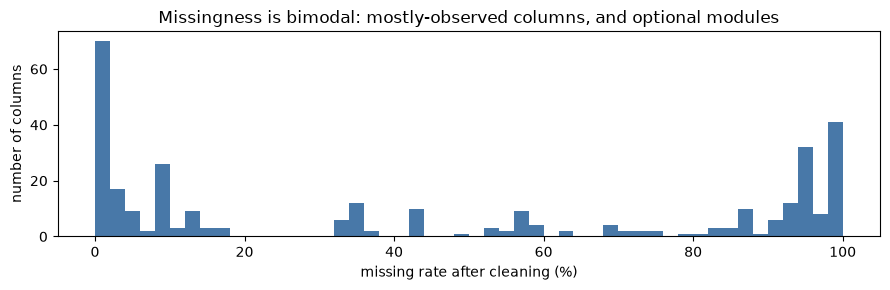

In [22]:
def missing_bands(M, names):
    m = np.isnan(M).mean(0)
    bands = {
        ">80%": [names[j] for j in range(len(names)) if m[j] > 0.80],
        "5-80%": [names[j] for j in range(len(names)) if 0.05 <= m[j] <= 0.80],
        "<5%": [names[j] for j in range(len(names)) if 0 < m[j] < 0.05],
        "0%": [names[j] for j in range(len(names)) if m[j] == 0],
    }
    return m, bands


miss, BANDS = missing_bands(X, names_full)
total = len(names_full)
for k, v in BANDS.items():
    print(f"{k:7s} {len(v):4d} columns  ({100 * len(v) / total:5.1f} %)")
print(f"{'total':7s} {total:4d}")

plt.figure(figsize=(9, 3))
plt.hist(100 * miss, bins=50, color="#4878a8")
plt.xlabel("missing rate after cleaning (%)")
plt.ylabel("number of columns")
plt.title("Missingness is bimodal: mostly-observed columns, and optional modules")
plt.tight_layout()
plt.show()

### 9.1 The `> 80 %` band and the *plateau* argument

Sorting the missing rates of this band shows **plateaus**: groups of columns sharing almost
exactly the same missing rate, to the row. That is not a coincidence — those columns are the
questions of one **optional module** that only some states ran, or the follow-ups of one filter
question. Every respondent who was not asked the module is missing on *all* of its questions,
hence the identical rate.

Two consequences:

* imputing them is meaningless: we would be inventing the answers of people who were never
  asked, for 80–99 % of the dataset;
* the only usable information they carry is **"was this person asked at all"**, which is a
  property of the state and the survey version, not of the person's health. That is exactly the
  kind of feature that inflates a validation score and does not generalise.

So the whole band is dropped, with one check: we look for a column in the band that is
nevertheless strongly associated with the label among the rows where it *is* observed, which
would justify an exception. The `gap` column below is the distance to the next missing rate and
makes the plateaus visible.

In [23]:
hi = sorted(((miss[col_index[n]], n) for n in BANDS[">80%"]), reverse=True)
print(f"{'column':14s} {'missing':>8s} {'gap':>6s}  {'observed':>8s}  section")
prev = None
for rate, n in hi:
    gap = 0.0 if prev is None else (prev - rate) * 100
    sec = META.get(n, {}).get("section", "")[:38]
    print(f"{n:14s} {100 * rate:7.2f}% {gap:5.2f}  {int((~np.isnan(X[:, col_index[n]])).sum()):8d}  {sec}")
    prev = rate
print(f"\n{len(hi)} columns in this band")

column          missing    gap  observed  section
LADULT           99.99%  0.00        32  
COLGHOUS         99.99%  0.00        32  
PCDMDECN         99.95%  0.04       175  Module 18.2 - Prostate Cancer Screenin
ASDRVIST         99.93%  0.01       222  Module 8.4 - Adult Asthma History
ASERVIST         99.93%  0.00       224  Module 8.3 - Adult Asthma History
ASNOSLEP         99.90%  0.03       332  Module 8.8 - Adult Asthma History
ASACTLIM         99.86%  0.04       458  Module 8.6 - Adult Asthma History
ASYMPTOM         99.86%  0.00       470  Module 8.7 - Adult Asthma History
ASTHMED3         99.86%  0.00       472  Module 8.9 - Adult Asthma History
ASRCHKUP         99.85%  0.00       476  Module 8.5 - Adult Asthma History
ASINHALR         99.85%  0.00       476  Module 8.10 - Adult Asthma History
ASATTACK         99.85%  0.00       481  Module 8.2 - Adult Asthma History
STREHAB1         99.84%  0.01       515  Module 9.2 - Cardiovascular Health
PCPSADE1         99.82%  0.02     

In [24]:
# Is any of them worth an exception? Association with the label, on observed rows only.
print("association with the label among observed rows, >80% band:\n")
rows, leaks = [], []
for n in BANDS[">80%"]:
    j = col_index[n]
    m = ~np.isnan(X[:, j])
    if m.sum() < 300:
        continue
    yy = y[m]
    # A column whose observed rows are ALL positives (or all negatives) is not a weak
    # feature with an undefined correlation: it is a question that was only asked to people
    # who already had the outcome. corrcoef would return nan and print a RuntimeWarning.
    if yy.std() == 0:
        leaks.append((n, int(m.sum()), float(yy.mean())))
        continue
    if np.nanstd(X[m, j]) == 0:
        continue
    rows.append((abs(np.corrcoef(X[m, j], yy)[0, 1]), n, int(m.sum())))

if leaks:
    print("LABEL IS CONSTANT ON THE OBSERVED ROWS -> post-event question, certain leakage:")
    for n, k, rate in leaks:
        print(f"  {n:12s} {k:7d} observed rows, all with y = {rate:.0f}   "
              f"{(META.get(n, {}).get('question', '') or '')[:46]}")
    print()

for c, n, k in sorted(rows, reverse=True)[:10]:
    print(f"  {n:14s} |corr| {c:.3f}  on {k:6d} rows   "
          f"({(META.get(n, {}).get('question', '') or '')[:50]})")
print("\nNothing here beats the columns we keep, and each is measured on a small,")
print("state-selected subsample -> the whole band is dropped. The leakage columns above")
print("are dropped for a second, stronger reason (section 10, reason 3).")

association with the label among observed rows, >80% band:

LABEL IS CONSTANT ON THE OBSERVED ROWS -> post-event question, certain leakage:
  HAREHAB1         758 observed rows, all with y = 1   Following your heart attack, did you go to any

  CVDASPRN       |corr| 0.257  on  14025 rows   (Do you take aspirin daily or every other day?)
  DRADVISE       |corr| 0.211  on  30410 rows   (Has a doctor or other health professional ever adv)
  ASACTLIM       |corr| 0.185  on    458 rows   (During the past 12 months, how many days were you )
  ASYMPTOM       |corr| 0.168  on    470 rows   (Symptoms of asthma include cough, wheezing, shortn)
  ASPUNSAF       |corr| 0.156  on   9761 rows   (Do you have a health problem or condition that mak)
  RDUCHART       |corr| 0.147  on   4077 rows   (Do you take aspirin to reduce the chance of a hear)
  ADENERGY       |corr| 0.137  on  14844 rows   (Over the last 2 weeks, how many days have you felt)
  ARTTODAY       |corr| 0.133  on  14489 rows   (Thinki

### 9.2 The `5 – 80 %` band — four diagnostics instead of one threshold

This band is the interesting one. A column here is usually a **conditional question**: it was
only asked to the respondents who answered something specific to a filter question
(`condition` in the codebook). `POORHLTH` for instance is only asked to people who reported at
least one bad physical or mental health day.

Dropping on the missing rate alone would throw away good features, so we score each column on
four measures and decide with all four in front of us:

1. **missing rate** — the cost of keeping it (how much has to be imputed).
2. **|corr| with the label** — the linear signal. Computed on observed rows only, because
   imputing first would drag the correlation towards 0.
3. **non-linearity** = spread of the positive rate across the deciles of the column.
   A column can be useless to a *linear* model (|corr| ≈ 0) and still be very informative;
   `_AGEG5YR` and the BMI categories behave like this. The measure is
   `max(rate per decile) − min(rate per decile)`: a large spread with a small correlation means
   "keep it, but encode it as categories rather than as a number".
4. **redundancy** = the largest |corr| with any *other* column. BRFSS ships both the raw
   question and one or several derived versions (`BPHIGH4` and `_RFHYPE5`, `WEIGHT2` and
   `_BMI5`). Keeping both adds collinearity without adding information, so of a redundant pair
   we keep the one that is better observed and easier to interpret.

In [25]:
def corr_with_label(col, yy):
    m = ~np.isnan(col)
    if m.sum() < 200:
        return np.nan
    v = col[m]
    if v.std() == 0:
        return np.nan
    return float(np.corrcoef(v, yy[m])[0, 1])


def decile_spread(col, yy, q=10):
    """Spread of the positive rate across quantile bins of the column: non-linear signal."""
    m = ~np.isnan(col)
    v, t = col[m], yy[m]
    if len(v) < 1000:
        return np.nan
    edges = np.unique(np.nanpercentile(v, np.linspace(0, 100, q + 1)))
    if len(edges) < 3:
        return np.nan
    b = np.clip(np.digitize(v, edges[1:-1]), 0, len(edges) - 2)
    rates = [t[b == k].mean() for k in range(len(edges) - 1) if (b == k).sum() >= 100]
    return float(max(rates) - min(rates)) if len(rates) >= 3 else np.nan


def redundancy(M, names, subset_idx, sample=20000, seed=0):
    """For each column of `subset_idx`, the max |corr| with any other column of the matrix."""
    rng = np.random.default_rng(seed)
    take = rng.choice(M.shape[0], size=min(sample, M.shape[0]), replace=False)
    S = M[take]
    # mean-impute only for this diagnostic; the real imputation happens later
    mu = np.nanmean(S, axis=0)
    mu = np.where(np.isnan(mu), 0.0, mu)
    S = np.where(np.isnan(S), mu, S)
    sd = S.std(0)
    ok = sd > 0
    Z = np.zeros_like(S)
    Z[:, ok] = (S[:, ok] - S[:, ok].mean(0)) / sd[ok]
    out = {}
    for j in subset_idx:
        if not ok[j]:
            out[names[j]] = (np.nan, "")
            continue
        c = np.abs(Z[:, ok].T @ Z[:, j]) / len(Z)
        idx_ok = np.flatnonzero(ok)
        c[idx_ok == j] = 0
        k = int(np.argmax(c))
        out[names[j]] = (float(c[k]), names[idx_ok[k]])
    return out


band_mid = BANDS["5-80%"]
idx_mid = [col_index[n] for n in band_mid]
RED = redundancy(X, names_full, idx_mid)

diag = []
for n in band_mid:
    j = col_index[n]
    diag.append({
        "name": n,
        "miss": miss[j],
        "corr": corr_with_label(X[:, j], y),
        "nonlin": decile_spread(X[:, j], y),
        "red": RED[n][0],
        "red_with": RED[n][1],
        "cond": (META.get(n, {}).get("condition", "") or "")[:40],
    })

def fmt(v):
    """nan means 'not computable here', not 'zero' — print it as a dash."""
    return "      -" if v is None or (isinstance(v, float) and np.isnan(v)) else f"{v:7.3f}"


diag.sort(key=lambda d: -(0 if np.isnan(d["corr"]) else abs(d["corr"])))
print(f"{'column':13s} {'miss':>6s} {'|corr|':>7s} {'nonlin':>7s} {'redund':>7s} "
      f"{'with':<12s} condition")
for d in diag:
    c = None if np.isnan(d["corr"]) else abs(d["corr"])
    print(f"{d['name']:13s} {100 * d['miss']:5.1f}% {fmt(c)} {fmt(d['nonlin'])} "
          f"{fmt(d['red'])} {d['red_with']:<12s} {d['cond']}")
print(f"\n{len(diag)} columns in the 5-80 % band")
print("nonlin is a dash for a binary column: there are no deciles to spread.")
print("|corr| is a dash when the column is constant on its observed rows — check those,")
print("they are usually administrative (everybody answered 1).")

column          miss  |corr|  nonlin  redund with         condition
PNEUVAC3       17.7%   0.183       -   0.543 _PNEUMO2     
TOLDHI2        14.1%   0.180       -   1.000 _RFCHOL      Section 5.01, BLOODCHO, is coded 2, 7, 9
_RFCHOL        14.1%   0.180       -   1.000 TOLDHI2      BLOODCHO=1 and TOLDHI2 = 2 | BLOODCHO=1 
POORHLTH       49.8%   0.159   0.178   0.498 PHYSHLTH     _ _ Number of days | Section 02.01, PHYS
INCOME2        17.9%   0.121   0.090   0.977 _INCOMG      If "no," code 02 | If "no," code 03; if 
_INCOMG        17.9%   0.120   0.086   0.977 INCOME2      INCOME2 = 1 or 2 | INCOME2 = 3 or 4 | IN
ARTHSOCL       69.5%   0.117       -   0.566 JOINPAIN     
CIMEMLOS       73.8%   0.115       -   0.239 DECIDE       Section 07.02, AGE, is less than 45
JOINPAIN       70.4%   0.115   0.132   0.566 ARTHSOCL     Section 06.09, HAVARTH3, is coded 2, 7, 
ACTIN11_       33.8%   0.109       -   0.658 METVL11_     
BPMEDS         59.9%   0.104       -   0.179 MAXVO2_      
CHOLCHK 

## 10. The drop list, with one written reason per column


| # | reason | argument |
|---|---|---|
| 1 | **identifier / survey administration** | `SEQNO`, `IDATE`, `DISPCODE`, `QSTVER`, ... describe the *interview*, not the person. A model that uses them is fitting the data-collection process. |
| 2 | **sampling weight / survey design** | `_LLCPWT`, `_STSTR`, `_PSU`, ... exist to make BRFSS estimates representative. They are functions of the respondent's state and stratum, so they leak geography and, through it, prevalence. |
| 3 | **label leakage / post-event** | `CVDINFR4` ("ever told you had a heart attack") and `CVDCRHD4` ("angina or coronary heart disease") are the two questions from which `_MICHD` is *defined*. Cardiac-rehab and aspirin-regimen questions (`HAREHAB1`, `CVDASPRN`, `RDUCHART`, ...) are only asked to people who already had the event; one of them was 100 % positive in our check. Keeping any of these gives a near-perfect score that means nothing. |
| 4 | **geography proxy** | `_STATE`, `MSCODE`, `_METSTAT` encode where the person lives. They carry real signal (state prevalence differs) but it is a property of the sampling frame, and the AIcrowd test set is a random split of the same states, so this signal is a shortcut we choose not to take; it also makes the model useless outside 2015 BRFSS. |
| 5 | **redundant derived duplicate** | BRFSS ships raw questions *and* CDC-computed versions. Of a redundant pair we keep the one that is better observed and easier to explain. |
| 6 | **optional module (> 80 % missing)** | computed in section 9.1, not typed by hand. |

Plus one automatic rule: a column that is **constant** after cleaning carries no information and
would make the normal equations singular, so it goes too.

Names that do not exist in this dataset are reported and ignored, so the lists are safe to
extend.

In [26]:
DROP_MANUAL = {
    "1_identifier_admin": [
        "SEQNO", "IDATE", "IMONTH", "IDAY", "IYEAR", "FMONTH", "DISPCODE", "QSTVER",
        "QSTLANG", "_DUALUSE", "_DUALCOR",
        # the telephone-frame bookkeeping: which sampling frame the respondent came from,
        # whether it is a private residence, how many phones. 2015 spells these several ways,
        # so both spellings are listed and the ones absent are reported below.
        "CTELENUM", "CTELENM1", "CTELNUM1", "PVTRESD1", "PVTRESD2", "PVTRESD3",
        "COLGHOUS", "CCLGHOUS", "STATERES", "STATERE1", "CSTATE", "CSTATE1",
        "CELLFON2", "CELLFON3", "CELLFON4", "CELLFON5", "LANDLINE", "LADULT", "CADULT",
        "HHADULT", "NUMADULT", "NUMMEN", "NUMWOMEN", "NUMHHOL2", "NUMPHON2", "CPDEMO1",
    ],
    "2_survey_weight_design": [
        "_PSU", "_STSTR", "_STRWT", "_RAWRAKE", "_WT2RAKE", "_LLCPWT", "_CLLCPWT",
        "_LLCPWT2", "_CHISPNC", "_CRACE1", "_CPRACE",
    ],
    "3_label_leakage": [
        "CVDINFR4", "CVDCRHD4", "_MICHD",
        "HAREHAB1", "STREHAB1", "CVDASPRN", "ASPUNSAF", "RLIVPAIN", "RDUCHART", "RDUCSTRK",
        "CVDSTRK3",
    ],
    "8_raw_date_code": [
        # MMYYYY packed into one integer: 122015 = December 2015, 772015 = month unknown.
        # As a number it is meaningless (012015 and 122015 are 110000 apart for 11 months) and
        # the fact itself is already in FLUSHOT6 / HIVTST6 as a yes/no question.
        "FLSHTMY2", "HIVTSTD3",
    ],
    "4_geography_proxy": [
        "_STATE", "MSCODE", "_METSTAT", "_URBSTAT",
    ],
    "5_redundant_derived": [
        "_RFHYPE5", "_RFCHOL", "_LTASTH1", "_CASTHM1", "_RFBMI5", "_RFSMOK3",
        "_RFDRHV5", "_RFSEAT2", "_RFSEAT3", "_PAINDX1", "_PA150R2", "_PA300R2",
        "_PASTRNG", "_PAREC1", "_FRTLT1", "_VEGLT1", "_TOTINDA",
        "_HCVU651",   # = HLTHPLN1 restricted to ages 18-64; its "9" is mostly "aged 65+"
        "PAMISS1_",   # the CDC's own missing-data flag for the PA block; our block flag covers it
        "EXERHMM1", "EXERHMM2",   # = PADUR1_ / PADUR2_, which the CDC already gives in minutes
    ],
}

present, absent = {}, {}
for reason, cols in DROP_MANUAL.items():
    present[reason] = [c for c in cols if c in col_index]
    absent[reason] = [c for c in cols if c not in col_index]
    print(f"{reason:24s} {len(present[reason]):3d} dropped"
          f"{'   (not in dataset: ' + ', '.join(absent[reason]) + ')' if absent[reason] else ''}")

drop_manual = sorted({c for v in present.values() for c in v})
drop_module = sorted(BANDS[">80%"])
const_mask = np.array([np.nanstd(X[:, j]) == 0 or np.isnan(X[:, j]).all()
                       for j in range(len(names_full))])
drop_const = [names_full[j] for j in np.flatnonzero(const_mask)]

DROP = sorted(set(drop_manual) | set(drop_module) | set(drop_const))
print(f"\nmanual reasons      : {len(drop_manual)}")
print(f"optional modules    : {len(drop_module)}")
print(f"constant after clean: {len(drop_const)} {drop_const}")
print(f"union to drop       : {len(DROP)}")
print(f"columns kept        : {len(names_full) - len(DROP)}")

1_identifier_admin        31 dropped   (not in dataset: CTELENM1, PVTRESD3, STATERE1, CSTATE1, CELLFON4, CELLFON5)
2_survey_weight_design    10 dropped   (not in dataset: _LLCPWT2)
3_label_leakage            8 dropped   (not in dataset: CVDINFR4, CVDCRHD4, _MICHD)
8_raw_date_code            2 dropped
4_geography_proxy          2 dropped   (not in dataset: _METSTAT, _URBSTAT)
5_redundant_derived       21 dropped

manual reasons      : 74
optional modules    : 117
constant after clean: 6 ['CTELENUM', 'COLGHOUS', 'STATERES', 'CTELNUM1', 'CELLFON2', 'CCLGHOUS']
union to drop       : 176
columns kept        : 145


In [27]:
def near_duplicates(M, names, idx, thresh=0.99, sample=20000, seed=0):
    """All pairs of columns of `idx` whose |correlation| reaches `thresh`."""
    rng = np.random.default_rng(seed)
    take = rng.choice(M.shape[0], size=min(sample, M.shape[0]), replace=False)
    S = M[np.ix_(take, idx)]
    mu = np.nanmean(S, axis=0)
    mu = np.where(np.isnan(mu), 0.0, mu)
    S = np.where(np.isnan(S), mu, S)
    sd = S.std(0)
    ok = sd > 0
    Z = (S[:, ok] - S[:, ok].mean(0)) / sd[ok]
    C = np.abs(Z.T @ Z) / len(Z)
    np.fill_diagonal(C, 0.0)
    cols = [names[idx[k]] for k in np.flatnonzero(ok)]
    a, b = np.where(np.triu(C >= thresh, 1))
    return sorted(((float(C[i, j]), cols[i], cols[j]) for i, j in zip(a, b)), reverse=True)


def derived_looking(name):
    return name.startswith("_") or name.endswith("_")


alive = [col_index[c] for c in names_full if c not in DROP]
pairs = near_duplicates(X, names_full, alive, thresh=0.99)

DUP_REASON, removed = {}, set()
print(f"{'corr':>6s}  {'pair':28s} {'missing':>16s}   dropped")
for c, a, b in pairs:
    if a in removed or b in removed:
        continue
    ma, mb = miss[col_index[a]], miss[col_index[b]]
    if abs(ma - mb) > 1e-9:
        loser = a if ma > mb else b
    else:
        loser = a if derived_looking(a) and not derived_looking(b) else (
            b if derived_looking(b) and not derived_looking(a) else max(a, b))
    keeper = b if loser == a else a
    removed.add(loser)
    DUP_REASON[loser] = f"9_near_duplicate_of_{keeper}"
    print(f"{c:6.3f}  {a + ' <-> ' + b:28s} {100 * ma:6.1f}% /{100 * mb:6.1f}%   {loser}")

if not pairs:
    print("  no pair above 0.99")

DROP = sorted(set(DROP) | removed)
print(f"\n{len(removed)} near-duplicates removed -> {len(names_full) - len(DROP)} columns kept")

  corr  pair                                  missing   dropped
 1.000  HAVARTH3 <-> _DRDXAR1           0.6% /   0.6%   _DRDXAR1
 1.000  _FRTRESP <-> _FRUITEX           0.0% /   0.0%   _FRUITEX
 1.000  HIVTST6 <-> _AIDTST3           13.0% /  13.0%   _AIDTST3
 1.000  EXEROFT2 <-> PAFREQ2_          55.7% /  55.7%   PAFREQ2_
 1.000  WEIGHT2 <-> WTKG3               7.0% /   7.0%   WTKG3
 1.000  MAXVO2_ <-> FC60_               1.2% /   1.2%   MAXVO2_
 1.000  FRUIT1 <-> FRUTDA1_             8.2% /   8.2%   FRUTDA1_
 1.000  FRUITJU1 <-> FTJUDA1_           8.6% /   8.6%   FTJUDA1_
 1.000  VEGETAB1 <-> VEGEDA1_           9.3% /   9.3%   VEGEDA1_
 1.000  FVGREEN <-> GRENDAY_            8.5% /   8.5%   GRENDAY_
 1.000  FVORANG <-> ORNGDAY_            8.8% /   8.8%   ORNGDAY_
 1.000  FVBEANS <-> BEANDAY_            9.0% /   9.0%   BEANDAY_
 1.000  ALCDAY5 <-> DROCDY3_            4.9% /   4.9%   DROCDY3_
 1.000  HEIGHT3 <-> HTM4                3.5% /   3.5%   HTM4
 0.999  _VEGRESP <-> _VEGETEX     

In [28]:
def condition_sources(name):
    """Column names that appear in the codebook `condition` field of `name`."""
    cond = META.get(name, {}).get("condition", "") or ""
    toks = set(re.findall(r"[A-Z_][A-Z0-9_]{2,}", cond))
    return sorted(t for t in toks if t in col_index and t != name)


def is_calculated(name):
    return "Calculated" in (META.get(name, {}).get("section", "") or "")


DERIVED_REASON = {}
print(f"{'column':11s} {'<- source':13s} {'|corr|':>7s} {'miss':>7s} {'src miss':>9s}  decision")
for n in names_full:
    if n in DROP or not is_calculated(n):
        continue
    src = [c for c in condition_sources(n) if c not in DROP]
    if len(src) != 1:
        continue
    a, b = X[:, col_index[n]], X[:, col_index[src[0]]]
    both = np.isfinite(a) & np.isfinite(b)
    c = (np.corrcoef(a[both], b[both])[0, 1]
         if both.sum() > 500 and a[both].std() > 0 and b[both].std() > 0 else np.nan)
    drop_it = np.isfinite(c) and abs(c) >= 0.50
    if drop_it:
        DERIVED_REASON[n] = f"10_recoding_of_{src[0]}"
    print(f"{n:11s} <- {src[0]:11s} "
          f"{abs(c) if np.isfinite(c) else float('nan'):7.3f} "
          f"{100 * miss[col_index[n]]:6.1f}% {100 * miss[col_index[src[0]]]:8.1f}%  "
          f"{'DROP' if drop_it else 'keep (correlation too low: skip logic, not a formula)'}")

DROP = sorted(set(DROP) | set(DERIVED_REASON))
print(f"\n{len(DERIVED_REASON)} single-source recodings dropped "
      f"-> {len(names_full) - len(DROP)} columns kept")

column      <- source      |corr|    miss  src miss  decision
_RFHLTH     <- GENHLTH       0.757    0.3%      0.3%  DROP
_ASTHMS1    <- ASTHMA3       0.960    0.7%      0.3%  DROP
_BMI5CAT    <- _BMI5         0.801    8.3%      8.3%  DROP
_INCOMG     <- INCOME2       0.977   17.9%     17.9%  DROP
METVL11_    <- EXERANY2        nan   33.1%      8.6%  keep (correlation too low: skip logic, not a formula)
_FLSHOT6    <- FLUSHOT6      1.000   68.7%     10.0%  DROP
_PNEUMO2    <- PNEUVAC3      1.000   69.7%     17.7%  DROP

6 single-source recodings dropped -> 121 columns kept


## 11. Structural zeros — where `nan` actually means "zero"

For a **conditional** question, a missing value is not a lost measurement: it is the answer
"the filter did not apply to me", and for these particular questions the filter not applying is
equivalent to a zero. Imputing the median instead would say the opposite of the truth.

| column | asked only if | what a missing value means |
|---|---|---|
| `POORHLTH` | at least one bad physical or mental health day | **0** poor-health days |
| `BPMEDS` | told they have high blood pressure | **0** = not taking blood-pressure medication |
| `JOINPAIN` | told they have arthritis / joint symptoms | **0** = no joint pain |
| `AVEDRNK2`, `DRNK3GE5`, `MAXDRNKS` | drank in the past 30 days | **0** drinks |
| `ALCDAY5` | — (the filter itself) | already handled by the `888 = none` rule |

Every other column with missing values keeps them as `nan` and is imputed in section 13, which
is the honest treatment when "missing" really means "unknown".

In [29]:
CONDITIONAL_ZERO = {
    "POORHLTH": "no bad physical/mental health day -> 0 poor-health days",
    "BPMEDS": "not hypertensive -> not on BP medication",
    "JOINPAIN": "no arthritis/joint symptoms -> no joint pain",
    "AVEDRNK2": "did not drink in the past 30 days -> 0 drinks",
    "DRNK3GE5": "did not drink -> 0 binge episodes",
    "MAXDRNKS": "did not drink -> 0 drinks at once",
}


def apply_conditional_zeros(M, names=None, verbose=False):
    names = names_full if names is None else names
    idx = {n: j for j, n in enumerate(names)}
    out = M  # in place is fine: the operation is idempotent (nan -> 0)
    for n, why in CONDITIONAL_ZERO.items():
        if n not in idx:
            continue
        j = idx[n]
        k = int(np.isnan(out[:, j]).sum())
        out[np.isnan(out[:, j]), j] = 0.0
        if verbose:
            print(f"  {n:10s} {k:6d} missing -> 0   ({why})")
    return out


print("train:")
X = apply_conditional_zeros(X, verbose=True)
XT = apply_conditional_zeros(XT)

train:
  POORHLTH   163417 missing -> 0   (no bad physical/mental health day -> 0 poor-health days)
  BPMEDS     196550 missing -> 0   (not hypertensive -> not on BP medication)
  JOINPAIN   231022 missing -> 0   (no arthritis/joint symptoms -> no joint pain)
  AVEDRNK2   173523 missing -> 0   (did not drink in the past 30 days -> 0 drinks)
  DRNK3GE5   173414 missing -> 0   (did not drink -> 0 binge episodes)
  MAXDRNKS   176367 missing -> 0   (did not drink -> 0 drinks at once)


## 12. Missingness flags

### The problem imputation creates

Section 15 will replace every remaining `nan` by the median of its column, because a matrix
product cannot be computed with holes in it. But look at what that does to `SEATBELT`, whose
median is 1 = "always wears a seatbelt":

| respondent | raw answer | after imputation | what the model sees |
|---|---|---|---|
| A | 1 (always) | 1 | always wears a seatbelt |
| B | `nan` (code 8: never drives) | **1** | always wears a seatbelt |

After imputation, A and B are **identical rows**, although B never gets into a car. We have not
filled a gap, we have invented an answer — and the model has no way of telling the two apart.

### The fix: keep the fact that the value was invented

For every kept column with at least 5 % missing values we add one extra binary column,
`<NAME>__isna`, equal to 1 where the value was missing and 0 where it was observed. The row for
B becomes `SEATBELT = 1, SEATBELT__isna = 1`, and it is no longer confused with A's
`SEATBELT = 1, SEATBELT__isna = 0`.

Why this actually repairs the damage, in one line of algebra. The model computes

$$z = \dots + w_{\text{seatbelt}} \cdot x + w_{\text{flag}} \cdot \mathbb{1}[x \text{ was missing}] + \dots$$

For an observed row the flag is 0 and the term is the usual $w \cdot x$. For an imputed row
$x$ is the median $m$, so the contribution is $w_{\text{seatbelt}} \cdot m + w_{\text{flag}}$:
a **constant of its own**, which the fit is free to choose. Whatever the median got wrong for
that group is absorbed by $w_{\text{flag}}$ instead of bending $w_{\text{seatbelt}}$, which
still has to fit the respondents who really answered. In plain terms: the model gets a separate
intercept for "people who did not answer this question", and can learn that they differ.

### Order matters

The flags are built **before** imputation, for the obvious reason that afterwards there are no
`nan` left to detect. And they are only built for columns above 5 % missing: below that, the
flag is almost all zeros, so it carries nearly no information while still costing a column and
a coefficient.

### Why we deduplicate them

Conditional questions come in **blocks**. The diabetes module (`INSULIN`, `BLDSUGAR`,
`FEETCHK2`, `DOCTDIAB`, `CHKHEMO3`, `EYEEXAM`, `DIABEYE`, `DIABEDU`) is missing for the same
93.5 % of respondents — the ones who are not diabetic. Their eight flags are not merely similar,
they are the **same vector**, bit for bit.

Putting eight copies of one column into `X` is not a small inefficiency:

* the columns are linearly dependent, so $X^\top X$ is **singular**. `least_squares` and
  `ridge_regression` solve $X^\top X w = X^\top y$ with `np.linalg.solve`, which raises
  `LinAlgError: Singular matrix`;
* gradient descent does not crash, but it splits one coefficient arbitrarily across eight
  weights. The prediction is unchanged, the weights become meaningless, and any
  regularisation penalty on $\lVert w \rVert^2$ is now computed on a quantity that depends on
  how the split happened to land;
* and we would have paid eight columns for one piece of information.

So we group the flags by their 0/1 pattern and keep **one flag per distinct skip pattern**,
named after the first column of the block. The cell prints each block it collapses, which is
also a nice map of the survey's structure: you can see the modules appear.

One caveat worth knowing. A flag is only worth its column if "missing" is a fact about the
*person*. Sometimes it is a fact about the *variable's universe* instead — `CIMEMLOS` is only
asked above age 45, so its flag is an age indicator in disguise. Section 12.1 tests for exactly
that.

In [30]:
keep_names = [n for n in names_full if n not in DROP]
keep_idx = [col_index[n] for n in keep_names]

X1 = X[:, keep_idx].copy()
XT1 = XT[:, keep_idx].copy()
names1 = list(keep_names)

miss_keep = np.isnan(X1).mean(0)
flag_cand = [j for j in range(len(names1)) if miss_keep[j] >= 0.05]
print(f"{len(flag_cand)} kept columns have >= 5 % missing values")

# deduplicate identical missingness patterns
seen, flag_cols, flag_names, blocks = {}, [], [], {}
for j in flag_cand:
    pat = np.isnan(X1[:, j])
    key = pat.tobytes()
    if key in seen:
        blocks[seen[key]].append(names1[j])
        continue
    seen[key] = names1[j]
    blocks[names1[j]] = [names1[j]]
    flag_cols.append(j)
    flag_names.append(names1[j] + "__isna")

print(f"-> {len(flag_names)} distinct skip patterns, i.e. {len(flag_names)} flag columns\n")
for lead, members in blocks.items():
    if len(members) > 1:
        print(f"  block flag {lead + '__isna':22s} covers {len(members):2d} columns: "
              f"{', '.join(members[:6])}{' ...' if len(members) > 6 else ''}")

F_tr = np.isnan(X1[:, flag_cols]).astype(np.float64)
F_te = np.isnan(XT1[:, flag_cols]).astype(np.float64)
X1 = np.hstack([X1, F_tr])
XT1 = np.hstack([XT1, F_te])
names1 = names1 + flag_names
print(f"\nmatrix with flags: train {X1.shape}, test {XT1.shape}")

55 kept columns have >= 5 % missing values
-> 54 distinct skip patterns, i.e. 54 flag columns

  block flag _PACAT1__isna          covers  2 columns: _PACAT1, _PA30021

matrix with flags: train (328135, 175), test (109379, 175)


## 13. Typing the columns: binary / nominal / ordinal / continuous

The type of a column decides how notebook 03 encodes it and how we impute it here, so it has to
be recorded explicitly:

* **binary** — two values. Nothing to do beyond mapping to 0/1 later.
* **nominal** — unordered categories (`MARITAL`, `EMPLOY1`, `_IMPRACE`). The numbers have no
  order: "3 = divorced" is not between "2" and "4" in any meaningful sense. These must be
  **one-hot encoded**, and one category must be dropped to avoid the dummy-variable trap
  (a full set of dummies sums to the intercept column, making `XᵀX` singular — this is exactly
  the bug that gave us a column with standard deviation `3.6e-07`).
* **ordinal** — ordered scales (`GENHLTH` 1–5, `_AGEG5YR` 1–13, `EDUCA`, `INCOME2`,
  `CHECKUP1` after our fix). They can be used as numbers, and where the decile diagnostic of
  section 9.2 showed strong non-linearity we will *also* try a one-hot version in notebook 03.
* **continuous** — counts and measurements (`WEIGHT2`, `_BMI5`, `PHYSHLTH`, the converted
  frequency columns).

The classification is a short list of known ordinal/nominal columns plus a fallback on the
number of distinct values, and it is printed in full so it can be checked.

**When in doubt, we label a small-cardinality integer column `nominal`**, and that asymmetry is
deliberate: one-hot encoding a column that was in fact ordinal only costs columns — the model
can still recover the monotone relationship, it is simply given more freedom — whereas treating
a nominal column as a number asserts an order that does not exist (`MARITAL`: "divorced" is not
twice "married") and that error cannot be undone downstream. The price is dimensionality, so the
cell prints how many dummy columns this implies; if that number gets out of hand, the fix is to
move specific columns into `ORDINAL_KNOWN` after looking at their decile curve in section 9.2,
not to lower the threshold blindly.

In [31]:
ORDINAL_KNOWN = {
    "GENHLTH", "CHECKUP1", "EYEEXAM", "SEATBELT", "EDUCA", "INCOME2", "_AGEG5YR", "_AGE_G",
    "_EDUCAG", "_INCOMG", "_BMI5CAT", "_SMOKER3", "_DRNKWEK", "_PACAT1", "_PHYS14D",
    "_MENT14D", "DIABAGE2", "MENTHLTH", "PHYSHLTH", "POORHLTH", "SLEPTIM1", "_FRUTSUM",
    "_VEGESUM", "ALCDAY5", "CHILDREN", "DIABETE3", "LASTDEN3", "RMVTETH3", "HIVTSTD3",
}
NOMINAL_KNOWN = {
    "MARITAL", "EMPLOY1", "RENTHOM1", "VETERAN3", "_IMPRACE", "_PRACE1", "_MRACE1",
    "_RACE", "_RACEG21", "_RACEGR3", "_HISPANC", "EXRACT11", "EXRACT21", "_CHLDCNT",
    "PERSDOC2", "MEDCOST", "CHCOCNCR", "CHCCOPD1",
}


def classify(col, name):
    v = col[~np.isnan(col)]
    u = np.unique(v)
    if len(u) <= 1:
        return "constant"
    if len(u) == 2:
        return "binary"
    if name.endswith("__isna"):
        return "binary"
    if name in ORDINAL_KNOWN:
        return "ordinal"
    if name in NOMINAL_KNOWN:
        return "nominal"
    integral = np.all(np.abs(u - np.round(u)) < 1e-9)
    if integral and len(u) <= 12:
        return "nominal"      # few unordered-looking integer codes
    if integral and len(u) <= 30:
        return "ordinal"
    return "continuous"


TYPES = {n: classify(X1[:, j], n) for j, n in enumerate(names1)}
BINARY = [n for n in names1 if TYPES[n] == "binary"]
NOMINAL = [n for n in names1 if TYPES[n] == "nominal"]
ORDINAL = [n for n in names1 if TYPES[n] == "ordinal"]
CONTINUOUS = [n for n in names1 if TYPES[n] == "continuous"]

for label, lst in [("binary", BINARY), ("nominal", NOMINAL),
                   ("ordinal", ORDINAL), ("continuous", CONTINUOUS)]:
    print(f"{label:11s} {len(lst):4d}")
print()
print("nominal   :", ", ".join(NOMINAL))
print()
print("continuous:", ", ".join(CONTINUOUS))

n_dummies = sum(len(np.unique(X1[~np.isnan(X1[:, names1.index(n)]), names1.index(n)])) - 1
                for n in NOMINAL)
print(f"\none-hot encoding the nominal columns (minus one reference category each) will add "
      f"about {n_dummies} columns in notebook 03 -> roughly {len(names1) + n_dummies - len(NOMINAL)} "
      f"features in total")
if n_dummies > 600:
    print("That is a lot of dummies for ~300k rows. Move the columns whose decile curve in")
    print("section 9.2 is monotone into ORDINAL_KNOWN to bring it down.")

binary        93
nominal       33
ordinal       18
continuous    31

nominal   : PERSDOC2, BPHIGH4, BPMEDS, CHOLCHK, MARITAL, RENTHOM1, EMPLOY1, SMOKDAY2, LASTSMK2, USENOW3, EXRACT11, EXRACT21, ARTHSOCL, JOINPAIN, IMFVPLAC, WHRTST10, SXORIENT, TRNSGNDR, _CHOLCHK, _PRACE1, _MRACE1, _RACE, _RACEGR3, _RACE_G1, _AGE65YR, _MISFRTN, _MISVEGN, _VEGETEX, ACTIN11_, ACTIN21_, _LMTACT1, _LMTWRK1, _LMTSCL1

continuous: WEIGHT2, HEIGHT3, AVEDRNK2, DRNK3GE5, MAXDRNKS, FRUITJU1, FRUIT1, FVBEANS, FVGREEN, FVORANG, VEGETAB1, EXEROFT1, EXEROFT2, STRENGTH, _AGE80, _BMI5, METVL11_, METVL21_, FC60_, PADUR1_, PADUR2_, PAFREQ1_, _MINAC11, _MINAC21, STRFREQ_, PAMIN11_, PAMIN21_, PA1MIN_, PAVIG11_, PAVIG21_, PA1VIGM_

one-hot encoding the nominal columns (minus one reference category each) will add about 277 columns in notebook 03 -> roughly 419 features in total


## 14. Winsorising the continuous columns

A few continuous columns keep extreme but legal values after cleaning: weights around 500 lb,
`PHYSHLTH` at 30 days, converted frequencies of 150 times per month. A single row like that
moves the standardisation statistics of the whole column, and with logistic regression on
standardised features it also moves the gradient: one sample with `x = 40` standard deviations
dominates the sum `Xᵀ(σ(Xw) − y)`.

We clip each continuous column at its **1st and 99th percentile**, computed **on the train set
only**, and apply those same two numbers to the test set. Using test data to choose the clipping
thresholds would be a (mild but real) form of leakage, and the percentiles are stored in the
output JSON so the transformation is reproducible.

Clipping rather than deleting: the rows are valid respondents, we only limit how far their
value can pull the fit.

In [32]:
WINSOR = {}
for n in CONTINUOUS:
    j = names1.index(n)
    lo, hi = np.nanpercentile(X1[:, j], [1, 99])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        continue
    before_hi = float(np.nanmax(X1[:, j]))
    X1[:, j] = np.clip(X1[:, j], lo, hi)
    XT1[:, j] = np.clip(XT1[:, j], lo, hi)
    WINSOR[n] = (float(lo), float(hi))
    print(f"  {n:12s} [{lo:9.2f}, {hi:9.2f}]   previous max {before_hi:10.2f}")

print(f"\n{len(WINSOR)} continuous columns winsorised at the 1st / 99th train percentile")

  WEIGHT2      [   102.00,    320.00]   previous max    2099.00
  HEIGHT3      [    59.00,     76.00]   previous max      95.00
  AVEDRNK2     [     0.00,      8.00]   previous max      76.00
  DRNK3GE5     [     0.00,     10.00]   previous max      76.00
  MAXDRNKS     [     0.00,     12.00]   previous max      76.00
  FRUITJU1     [     0.00,     90.00]   previous max    2970.00
  FRUIT1       [     0.00,    120.00]   previous max    2970.00
  FVBEANS      [     0.00,     60.00]   previous max    2970.00
  FVGREEN      [     0.00,     90.00]   previous max    2970.00
  FVORANG      [     0.00,     60.00]   previous max    2970.00
  VEGETAB1     [     0.00,     90.00]   previous max    2970.00
  EXEROFT1     [     2.00,     60.00]   previous max     424.29
  EXEROFT2     [     1.00,     42.86]   previous max     424.29
  STRENGTH     [     0.00,     30.00]   previous max     424.29
  _AGE80       [    19.00,     80.00]   previous max      80.00
  _BMI5        [    17.92,     49.43]   

## 15. Imputation

Everything that is still `nan` at this point is genuinely unknown (the structural zeros were
handled in section 11 and the skip patterns are recorded in the flags of section 12), so it has
to be filled with something before a matrix product can be computed.

* **continuous / ordinal** &rarr; the **median** of the train column. The median is preferred to
  the mean because these distributions are skewed and bounded (a count of days, a weight); the
  mean of `PHYSHLTH` sits between two impossible-in-practice values, the median does not.
* **nominal / binary** &rarr; the **mode** (most frequent category), the only choice that keeps
  the column inside its own set of categories.

All statistics come from the **train set** and are applied unchanged to the test set. They are
saved in the JSON so notebook 03 and the submission script use exactly the same numbers.

In [33]:
IMPUTE = {}
for j, n in enumerate(names1):
    col = X1[:, j]
    m = np.isnan(col)
    if not m.any() and not np.isnan(XT1[:, j]).any():
        continue
    obs = col[~m]
    if len(obs) == 0:
        fill = 0.0
    elif TYPES[n] in ("continuous", "ordinal"):
        fill = float(np.median(obs))
    else:
        vals, cnt = np.unique(obs, return_counts=True)
        fill = float(vals[np.argmax(cnt)])
    X1[m, j] = fill
    XT1[np.isnan(XT1[:, j]), j] = fill
    IMPUTE[n] = {"value": fill, "rule": "median" if TYPES[n] in ("continuous", "ordinal") else "mode",
                 "train_missing": float(m.mean())}

print(f"{len(IMPUTE)} columns imputed")
worst = sorted(IMPUTE.items(), key=lambda kv: -kv[1]["train_missing"])[:12]
print(f"\n{'column':14s} {'missing':>8s} {'rule':>7s} {'value':>10s}")
for n, d in worst:
    print(f"{n:14s} {100 * d['train_missing']:7.2f}% {d['rule']:>7s} {d['value']:10.2f}")

assert not np.isnan(X1).any(), "train still contains nan"
assert not np.isnan(XT1).any(), "test still contains nan"
print("\nno nan left in either matrix")

103 columns imputed

column          missing    rule      value
CAREGIV1         75.49%    mode       2.00
WHRTST10         74.73%    mode       1.00
CIMEMLOS         73.83%    mode       2.00
LASTSMK2         72.53%    mode       7.00
ARTHDIS2         70.10%    mode       2.00
LMTJOIN3         69.52%    mode       2.00
ARTHSOCL         69.51%    mode       3.00
SXORIENT         63.20%    mode       1.00
TRNSGNDR         62.72%    mode       4.00
SMOKDAY2         58.40%    mode       3.00
IMFVPLAC         56.84%    mode       1.00
PADUR2_          56.27%  median      45.00

no nan left in either matrix


## 16. Final checks before saving

Six assertions, because a silent mistake here propagates into every experiment we run
afterwards:

1. train and test have the **same number of columns, in the same order**;
2. the column names are **unique**;
3. no `nan`, no `inf`;
4. no **constant** column (it would be redundant with the intercept and make `XᵀX` singular);
5. the number of rows matches the number of labels;
6. the label is still `{0, 1}` with the imbalance we started from.

In [34]:
problems = []

if X1.shape[1] != XT1.shape[1]:
    problems.append("train/test column count differs")
if len(set(names1)) != len(names1):
    dup = [n for n in set(names1) if names1.count(n) > 1]
    problems.append(f"duplicate column names: {dup}")
if not np.isfinite(X1).all() or not np.isfinite(XT1).all():
    problems.append("non-finite values remain")
sd = X1.std(0)
if (sd == 0).any():
    problems.append(f"constant columns: {[names1[j] for j in np.flatnonzero(sd == 0)]}")
if X1.shape[0] != len(y):
    problems.append("rows != labels")
if set(np.unique(y)) != {0.0, 1.0}:
    problems.append("label is not 0/1")

print("checks:", "ALL PASSED" if not problems else "FAILED")
for p in problems:
    print("  -", p)

print(f"\ntrain matrix : {X1.shape}")
print(f"test matrix  : {XT1.shape}")
print(f"labels       : {y.shape}, {100 * y.mean():.2f} % positive")
print(f"smallest std : {sd.min():.3e}  (must be > 0)")
print(f"largest |x|  : {np.abs(X1).max():.1f}")

checks: ALL PASSED

train matrix : (328135, 175)
test matrix  : (109379, 175)
labels       : (328135,), 8.83 % positive
smallest std : 1.090e-02  (must be > 0)
largest |x|  : 53200.0


In [35]:
# Drop any column that is constant *after* imputation (it can happen if a column was
# almost entirely missing and got filled with a single value). Nothing should be dropped here
# if the checks above passed; the code is kept so the notebook cannot produce a broken matrix.
ok = X1.std(0) > 0
if not ok.all():
    print("removing", [names1[j] for j in np.flatnonzero(~ok)])
    X1, XT1 = X1[:, ok], XT1[:, ok]
    names1 = [n for j, n in enumerate(names1) if ok[j]]
print("final shape:", X1.shape)

final shape: (328135, 175)


## 17. Saving the cleaned dataset

Two artefacts, plus one CSV for the report.

**`data/cache/cleaned.npz`** (compressed, `float32` — halves the file and the values are small
integers or one-decimal measurements):

| key | content |
|---|---|
| `X` | cleaned train matrix, `(n_train, n_features)` |
| `XT` | cleaned test matrix, same columns in the same order |
| `y` | labels in `{0, 1}` |
| `ids_tr`, `ids_te` | the `Id` column of each file, needed to write the submission |
| `names` | the column names, so the matrix stays interpretable |

**`notebooks/column_types.json`** — the metadata notebook 03 needs to encode the columns the
same way: the type of every column, the winsorising bounds, the imputation values and rules, the
drop list with its reason, and the flag blocks.

**`notebooks/dropped_columns.csv`** — one row per dropped column with its reason, ready to paste
into the report appendix.

The `data/` folder is in `.gitignore`, so `cleaned.npz` stays local: anyone on the team
regenerates it in a few seconds by running this notebook. The two small metadata files under
`notebooks/` *are* committed, so the team shares the same encoding decisions.

In [36]:
out_npz = CACHE / "cleaned.npz"
out_json = HERE / "column_types.json"
out_csv = HERE / "dropped_columns.csv"

np.savez_compressed(
    out_npz,
    X=X1.astype(np.float32),
    XT=XT1.astype(np.float32),
    y=y.astype(np.float32),
    ids_tr=ids_tr,
    ids_te=ids_te,
    names=np.array(names1),
)

reason_of = {}
for reason, cols in present.items():
    for c in cols:
        reason_of[c] = reason
for c in drop_module:
    reason_of.setdefault(c, "6_optional_module_over80pct_missing")
for c in drop_const:
    reason_of.setdefault(c, "7_constant_after_cleaning")
for c, r in DUP_REASON.items():
    reason_of.setdefault(c, r)
for c, r in DERIVED_REASON.items():
    reason_of.setdefault(c, r)
meta_out = {
    "n_train": int(X1.shape[0]),
    "n_test": int(XT1.shape[0]),
    "n_features": int(X1.shape[1]),
    "names": names1,
    "types": {n: TYPES.get(n, "binary") for n in names1},
    "binary": [n for n in names1 if TYPES.get(n) == "binary"],
    "nominal": [n for n in names1 if TYPES.get(n) == "nominal"],
    "ordinal": [n for n in names1 if TYPES.get(n) == "ordinal"],
    "continuous": [n for n in names1 if TYPES.get(n) == "continuous"],
    "winsor": WINSOR,
    "impute": IMPUTE,
    "flag_blocks": blocks,
    "conditional_zero": CONDITIONAL_ZERO,
    "dropped": reason_of,
    "sentinels": sorted(SENTINELS),
    "manual_rules": MANUAL,
    "never_touch": sorted(NEVER_TOUCH),
    "positive_rate": float(y.mean()),
}
out_json.write_text(json.dumps(meta_out, indent=1))

lines = ["column,reason,missing_rate_after_cleaning,question"]
for c, r in sorted(reason_of.items(), key=lambda kv: (kv[1], kv[0])):
    q = (META.get(c, {}).get("question", "") or "").replace('"', "'")[:90]
    mr = f"{100 * miss[col_index[c]]:.2f}" if c in col_index else ""
    lines.append(f'{c},{r},{mr},"{q}"')
out_csv.write_text("\n".join(lines))

print(f"{out_npz}   {out_npz.stat().st_size / 1e6:.1f} MB")
print(f"{out_json}  {out_json.stat().st_size / 1e3:.1f} kB")
print(f"{out_csv}   {len(lines) - 1} dropped columns")

chk = np.load(out_npz, allow_pickle=False)
print("\nreloaded:", {k: chk[k].shape for k in chk.files})
assert chk["X"].shape[1] == chk["XT"].shape[1] == len(chk["names"])
print("round-trip OK")

/home/projects-ML-2026/project-1/data/cache/cleaned.npz   43.4 MB
/home/projects-ML-2026/project-1/notebooks/column_types.json  33.7 kB
/home/projects-ML-2026/project-1/notebooks/dropped_columns.csv   200 dropped columns

reloaded: {'X': (328135, 175), 'XT': (109379, 175), 'y': (328135,), 'ids_tr': (328135,), 'ids_te': (109379,), 'names': (175,)}
round-trip OK


## 18. Sanity check — does the cleaned matrix train?

This is **not** the modelling notebook: no cross-validation, no hyperparameter search, no
submission. It is a 30-second smoke test whose only purpose is to catch a broken output before
we build on it. We standardise with train statistics, add an intercept, run our own
`logistic_regression` from `implementations.py` for a few hundred steps, and look at the F1 on a
held-out 20 %.

If this prints an F1 clearly above 0 and a loss that decreases, the cleaned matrix is usable.
The real tuning — step size, regularisation, decision threshold, one-hot encoding of the nominal
columns, feature interactions — happens in `03_modelling.ipynb`.

One thing worth remembering from our experiments: the decision **threshold** matters as much as
the model. At the default 0.5 a logistic regression on this 1:10 imbalance predicts almost only
zeros; F1 peaks well below 0.5, and that threshold has to be chosen on validation data, never on
the test set.

In [37]:
from implementations import logistic_regression

rng = np.random.default_rng(0)
perm = rng.permutation(len(y))
cut = int(0.8 * len(y))
itr, iva = perm[:cut], perm[cut:]

mu, sg = X1[itr].mean(0), X1[itr].std(0)
sg[sg == 0] = 1.0


def prep(A):
    return np.hstack([np.ones((len(A), 1)), (A - mu) / sg])


Atr, Ava = prep(X1[itr]), prep(X1[iva])
w0 = np.zeros(Atr.shape[1])
w, loss = logistic_regression(y[itr], Atr, w0, max_iters=500, gamma=0.5)
print(f"final training loss: {loss:.4f}")


def f1_at(th, p, t):
    pred = (p >= th).astype(float)
    tp = ((pred == 1) & (t == 1)).sum()
    fp = ((pred == 1) & (t == 0)).sum()
    fn = ((pred == 0) & (t == 1)).sum()
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return (2 * prec * rec / (prec + rec) if prec + rec else 0.0), prec, rec


z = Ava @ w
p = 1 / (1 + np.exp(-np.clip(z, -30, 30)))
best = max(((f1_at(t, p, y[iva])[0], t) for t in np.linspace(0.05, 0.6, 56)))
f1_05, pr_05, rc_05 = f1_at(0.5, p, y[iva])
f1_b, pr_b, rc_b = f1_at(best[1], p, y[iva])
print(f"threshold 0.50      : F1 {f1_05:.4f}  precision {pr_05:.3f}  recall {rc_05:.3f}")
print(f"threshold {best[1]:.2f} (best): F1 {f1_b:.4f}  precision {pr_b:.3f}  recall {rc_b:.3f}")
print(f"accuracy at 0.50    : {((p >= 0.5) == y[iva]).mean():.4f}   "
      f"(always-zero baseline: {1 - y[iva].mean():.4f})")

final training loss: 0.2243
threshold 0.50      : F1 0.1961  precision 0.563  recall 0.119
threshold 0.20 (best): F1 0.4182  precision 0.345  recall 0.532
accuracy at 0.50    : 0.9135   (always-zero baseline: 0.9112)


## 19. Summary — what this notebook did

1. **Loaded** the raw CSVs with a fast parser and a `.npy` cache; separated the `Id` column and
   mapped the label to `{0, 1}` (about 9 % positive).
2. **Recoded the special values** using the codebook extracted from the CDC PDF, restricted to a
   whitelist of the codes BRFSS actually uses. `7 / 9 / 77 / 99 / 777 / 999 / 7777 / 9999`
   became `nan`, `88 / 888` ("none") became `0`, and 20 administrative columns were protected
   from the recoding because their real values collide with those codes.
3. **Decoded the unit-encoded ranges** (`1xx` per week, `2xx` per month, `9xxx` kilograms) so
   that the frequency, weight and height columns are on a single interpretable scale.
4. **Restored three off-scale categories** by hand (`CHECKUP1`, `EYEEXAM` at level 5 = "never";
   `SEATBELT = 8` kept as missing and carried by its flag).
5. **Measured** missingness, association with the label, non-linearity and redundancy on the
   *cleaned* matrix — in that order, because doing it before recoding gives wrong numbers.
6. **Dropped** columns with an explicit written reason each: identifiers and survey
   administration, sampling weights, label leakage (`CVDINFR4` and `CVDCRHD4` define the
   target), geography proxies, redundant CDC-derived duplicates, optional modules above 80 %
   missing, and constant columns.
7. **Filled the structural zeros** where a skipped question means zero rather than unknown.
8. **Added one flag per distinct skip pattern**, so "this was not asked" stays in the data
   without duplicating collinear columns.
9. **Typed** every surviving column (binary / nominal / ordinal / continuous), winsorised the
   continuous ones at the train 1st/99th percentile, and imputed with train medians and modes.
10. **Saved** `cleaned.npz`, `column_types.json` and `dropped_columns.csv`, and verified the
    round-trip plus a smoke-test logistic regression.

### What is deliberately *not* here

* **One-hot encoding** of the nominal columns, polynomial or interaction features:
  they belong to notebook 03 because they change with the model and with the CV fold.
* **Standardisation** of the stored matrix: we keep the interpretable units on disk and
  standardise inside each training run with the statistics of that run's training fold. That is
  the only way cross-validation stays honest.
* **Class-imbalance handling** (class weights, threshold tuning): a modelling decision, and the
  smoke test above already shows why the threshold cannot stay at 0.5.

### Next step

`03_modelling.ipynb`: load `cleaned.npz` and `column_types.json`, one-hot encode the nominal
columns (dropping one reference category per column), then cross-validate the six
implementations with a grid over `gamma`, `lambda_` and the decision threshold, optimising
**F1** rather than accuracy.